# Generative Adversarial Network

Implementation and training of a Generative Adversarial Network (GAN) on the MNIST dataset. 

![GAN](https://www.kdnuggets.com/wp-content/uploads//generative-adversarial-network.png)

## Helper Functions

In [2]:
%matplotlib inline

import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import math
from tqdm.notebook import tqdm
from IPython import display
from tqdm import tqdm

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check if CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


In [3]:
def load_mnist(batch_size=64, val_split=0.1):
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
    full_train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
    
    # Calculate split sizes
    val_size = int(len(full_train_dataset) * val_split)
    train_size = len(full_train_dataset) - val_size
    
    # Split training dataset into train and validation
    train_dataset, val_dataset = torch.utils.data.random_split(
        full_train_dataset, 
        [train_size, val_size],
        generator=torch.Generator().manual_seed(42)
    )
    
    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    
    return train_loader, val_loader, test_loader

def save_checkpoint(model, optimizer, epoch, loss, save_path='checkpoints'):
    os.makedirs(save_path, exist_ok=True)
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': loss,
    }
    checkpoint_path = os.path.join(save_path, f'checkpoint_epoch_{epoch}.pt')
    torch.save(checkpoint, checkpoint_path)
    print(f"Checkpoint saved: {checkpoint_path}")

def load_checkpoint(model, optimizer, checkpoint_path):
    checkpoint = torch.load(checkpoint_path)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    return checkpoint['epoch'], checkpoint['loss']

def visualize_progress(metrics, display_handle=None, display_id='visualization'):
    max_cols = 4
    n_plots = len(metrics)
    n_cols = min(n_plots, max_cols)
    n_rows = math.ceil(n_plots / n_cols)
    figsize = (15, 3 * n_rows)
    fig = plt.figure(num=200, figsize=figsize)
    plt.clf()  # Clear the current figure
    for idx, name in enumerate(list(metrics.keys())):
        if name != 'images':
            plt.subplot(n_rows, n_cols, idx + 1)
            if len(metrics[name]) > 0:  # Only plot if we have data
                plt.plot(metrics[name], label=name)
            plt.title(name)
            plt.xlabel('Iteration')
            plt.ylabel('Value')
            plt.grid(True)
    
    images = metrics.get('images', None)
    if images is not None:
        ax = plt.subplot(n_rows, n_cols, n_plots)
        ax.set_title('Visualization')
        plt.imshow(images)
        plt.axis('off')
    
    plt.tight_layout()
    if display_handle is None:
        display_handle = display.display(display.HTML(''), display_id=display_id)
    display_handle.update(fig)
    plt.close()
    return display_handle

## MNIST Classifier Implementation and Training 

Training a Convolutional Neural Network (CNN) classifier on the MNIST dataset to learn the dataset.

In [24]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super(MNISTClassifier, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )
        
    def forward(self, x):
        return self.model(x)

### Evaluation Loop

In [1]:
def evaluate_classifier(model, test_loader, verbose=True):
    model.eval()
    
    correct = 0
    total = 0
    class_correct = [0] * 10
    class_total = [0] * 10
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device) # Load data to your device

            output = model(images)
            pred_labels = torch.argmax(output, dim=1)
            matches = pred_labels == labels

            correct += matches.sum().item()
            total += labels.size(0)

            for i in range(10):
                mask = labels == i
                class_total[i] += mask.sum().item()
                class_correct[i] += (matches & mask).sum().item()
    
    accuracy = 100 * correct / total
    if verbose:
        print(f'Overall Accuracy: {accuracy:.2f}%')
        for i in range(10):
            class_acc = 100 * class_correct[i] / class_total[i]
            print(f'Accuracy of digit {i}: {class_acc:.2f}%')
    return accuracy

### Training Loop

Epoch 1/3:   6%|████████▊                                                                                                                                              | 49/844 [00:24<06:14,  2.12it/s]

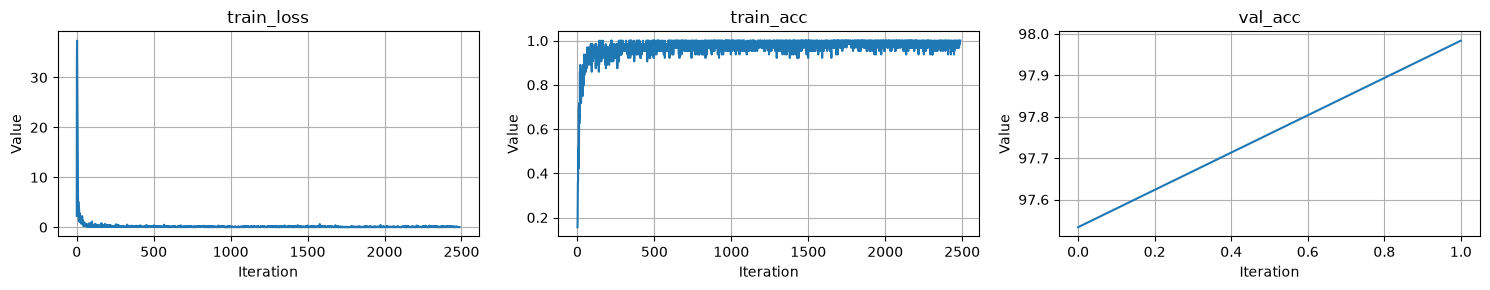

Epoch 3/3: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 844/844 [05:27<00:00,  2.58it/s]


Overall Accuracy: 97.72%
Accuracy of digit 0: 98.27%
Accuracy of digit 1: 98.77%
Accuracy of digit 2: 97.38%
Accuracy of digit 3: 98.81%
Accuracy of digit 4: 96.33%
Accuracy of digit 5: 99.22%
Accuracy of digit 6: 99.06%
Accuracy of digit 7: 98.83%
Accuracy of digit 8: 93.63%
Accuracy of digit 9: 96.83%


In [30]:
def train_classifier(model, train_loader, val_loader, num_epochs=3, learning_rate=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    model = model.to(device)
    visual_metric = {'train_loss': [], 'train_acc': [], 'val_acc': []}
    display_handle = None
    for epoch in range(num_epochs):
        model.train()
        for i, (images, labels) in enumerate(tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')):
            images, labels = images.to(device), labels.to(device)
            
            output = model(images)
            predictions = torch.argmax(output, dim=1)
            loss = criterion(output, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            visual_metric['train_loss'].append(loss.item())
            visual_metric['train_acc'].append((predictions == labels).sum().item() / labels.shape[0])
            
            if (i + 1) % 50 == 0:
               display_handle = visualize_progress(visual_metric, 
                                                   display_handle, 
                                                   display_id='classification')
        
        val_acc = evaluate_classifier(model, val_loader, verbose=False)
        visual_metric['val_acc'].append(val_acc)

model = MNISTClassifier()
train_loader, val_loader, test_loader = load_mnist()
train_classifier(model, train_loader, val_loader, num_epochs=3)
eval_accuracy = evaluate_classifier(model, test_loader)

## GAN Implementation and Training

In [26]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.MaxPool2d(2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return torch.sigmoid(self.model(x))
    
class Generator(nn.Module):
    def __init__(self, latent_dim=128):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(latent_dim, 128 * 7 * 7),
            nn.ReLU(),
            nn.Unflatten(1, (128, 7, 7)),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )


    def forward(self, z):
        return self.model(z)
        
def weights_init(m):
    """Initialize network weights."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, mean=0.0, std=0.02)

        if m.bias is not None:
            nn.init.zeros_(m.bias)

    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, mean=1.0, std=0.02)
        nn.init.zeros_(m.bias)

### Training Loop

Starting Training...


  0%|                                                                                                                                                                           | 0/938 [00:00<?, ?it/s]

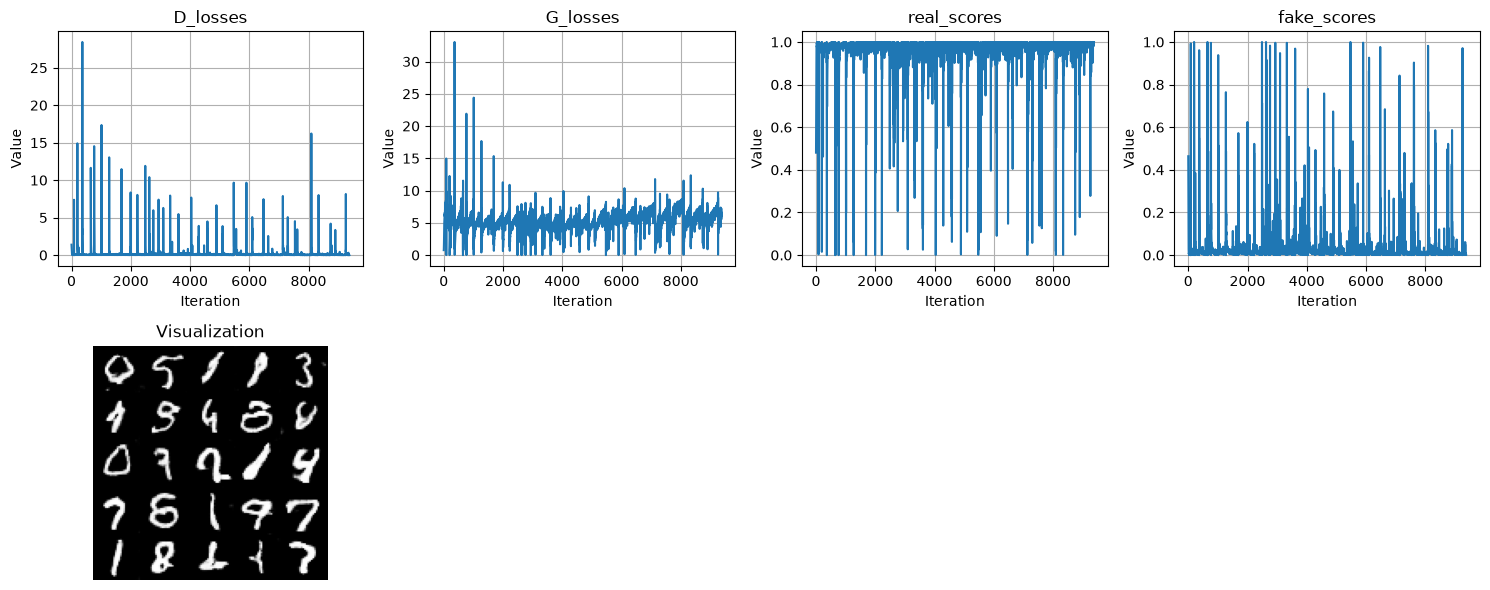

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:56<00:00,  3.97it/s]


Epoch 1/10


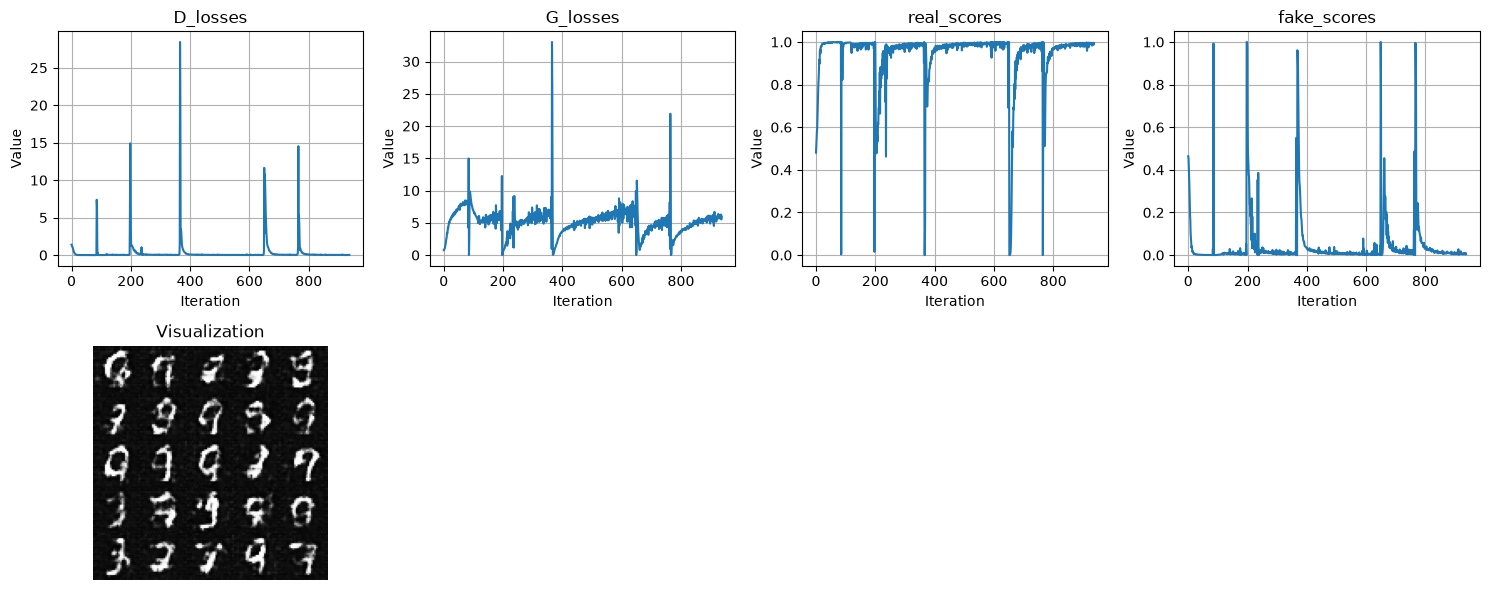

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:22<00:00,  4.63it/s]


Epoch 2/10


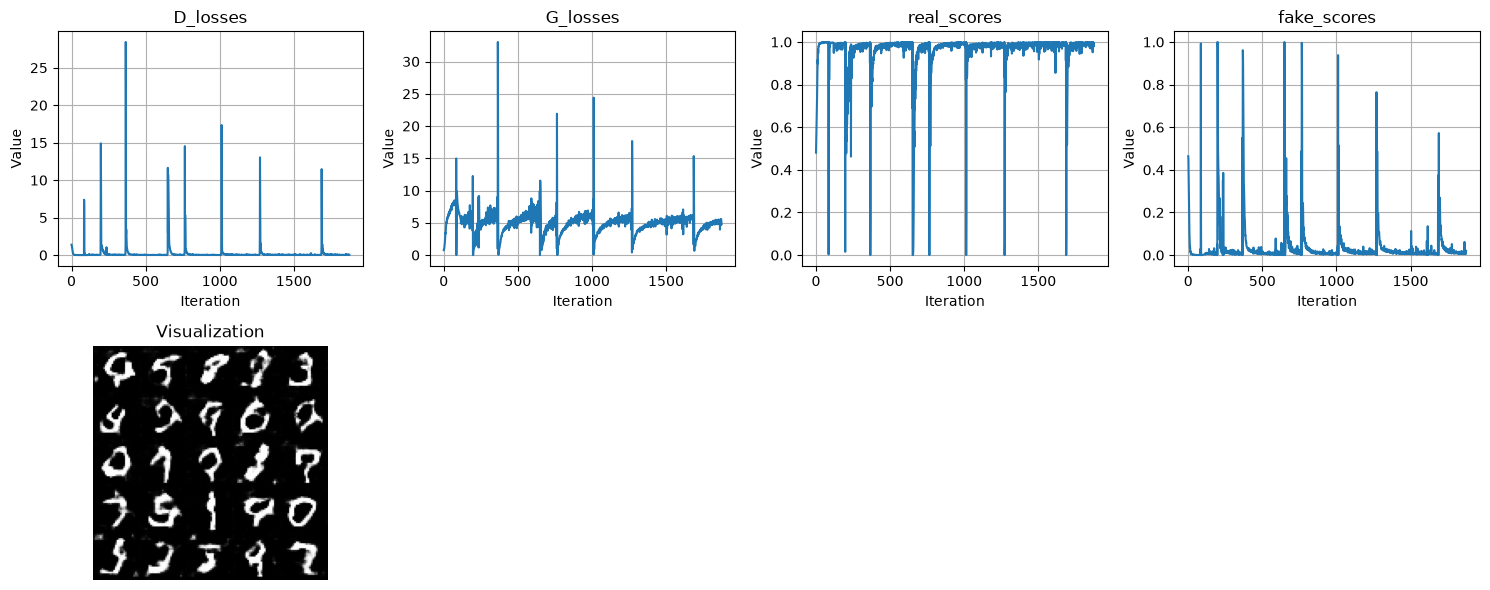

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:19<00:00,  4.71it/s]


Epoch 3/10


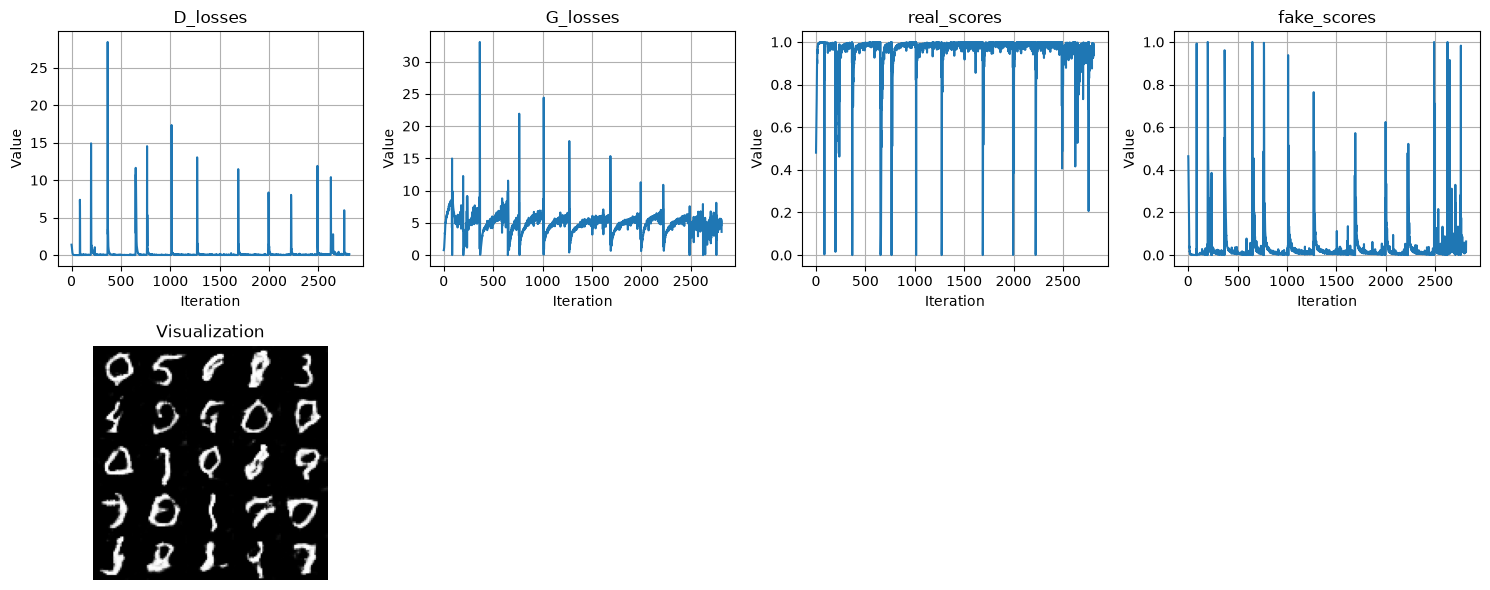

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:21<00:00,  4.66it/s]


Epoch 4/10


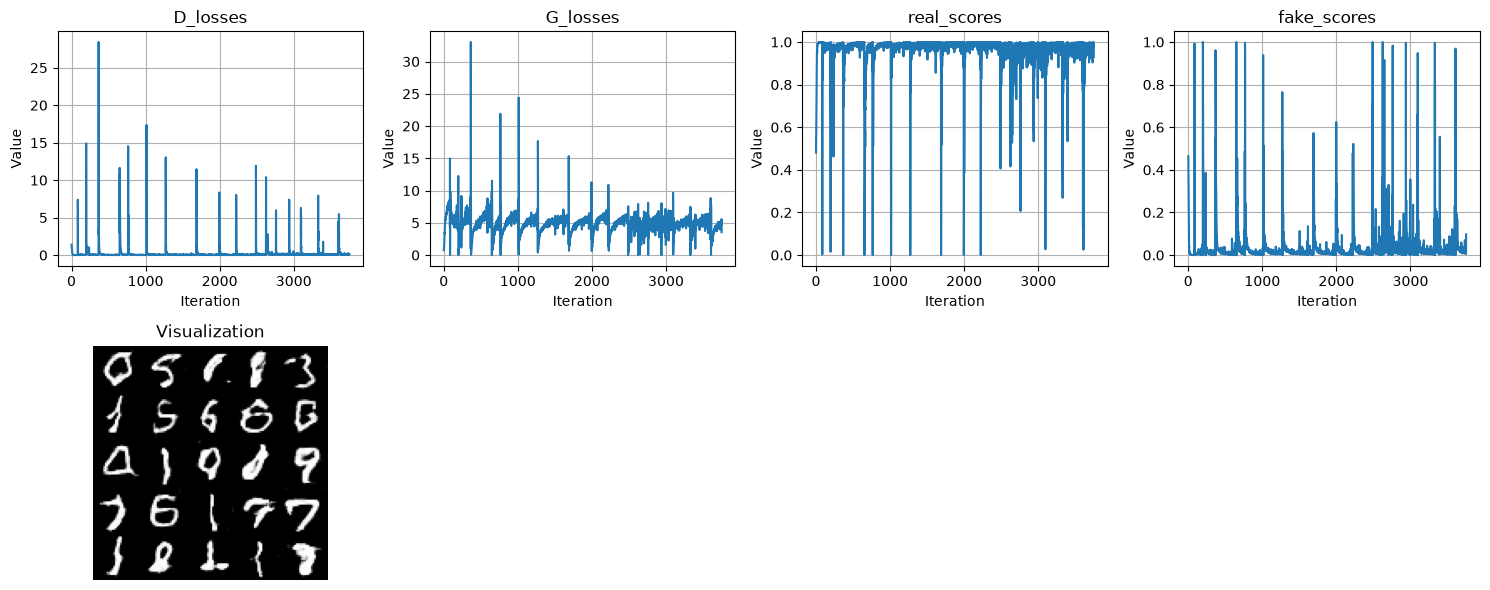

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:17<00:00,  4.75it/s]


Epoch 5/10


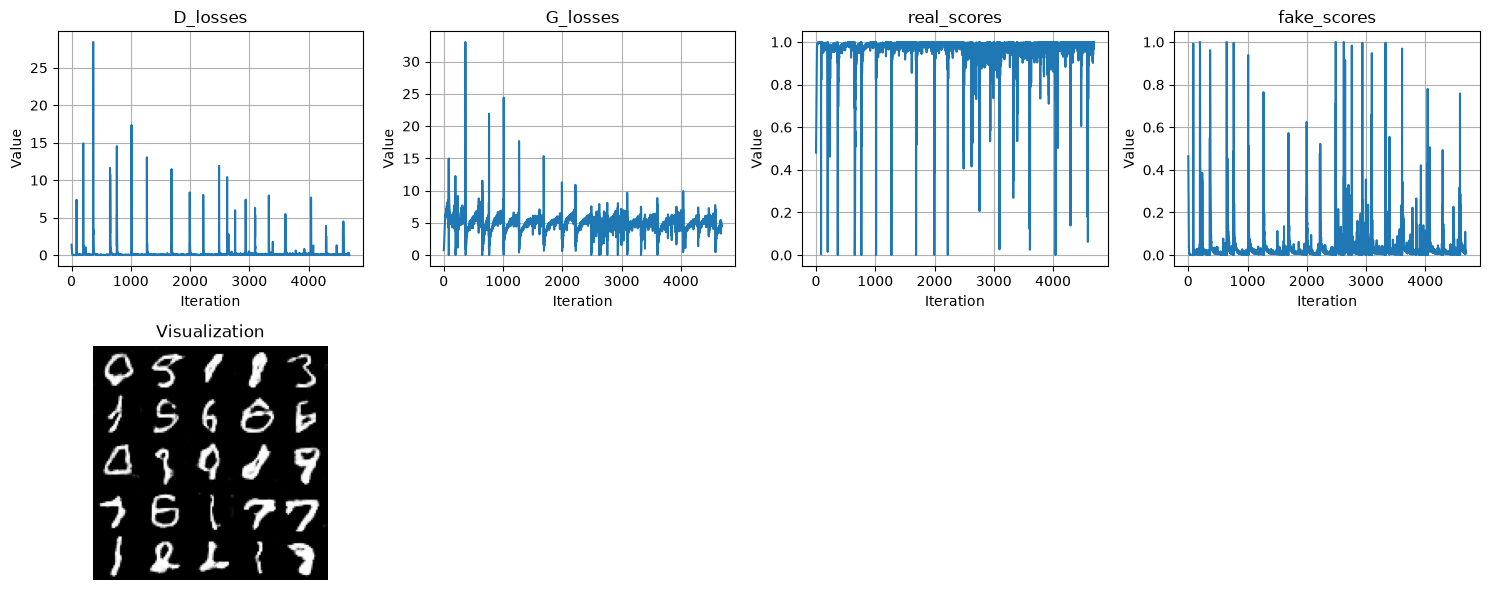

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:17<00:00,  4.74it/s]


Epoch 6/10


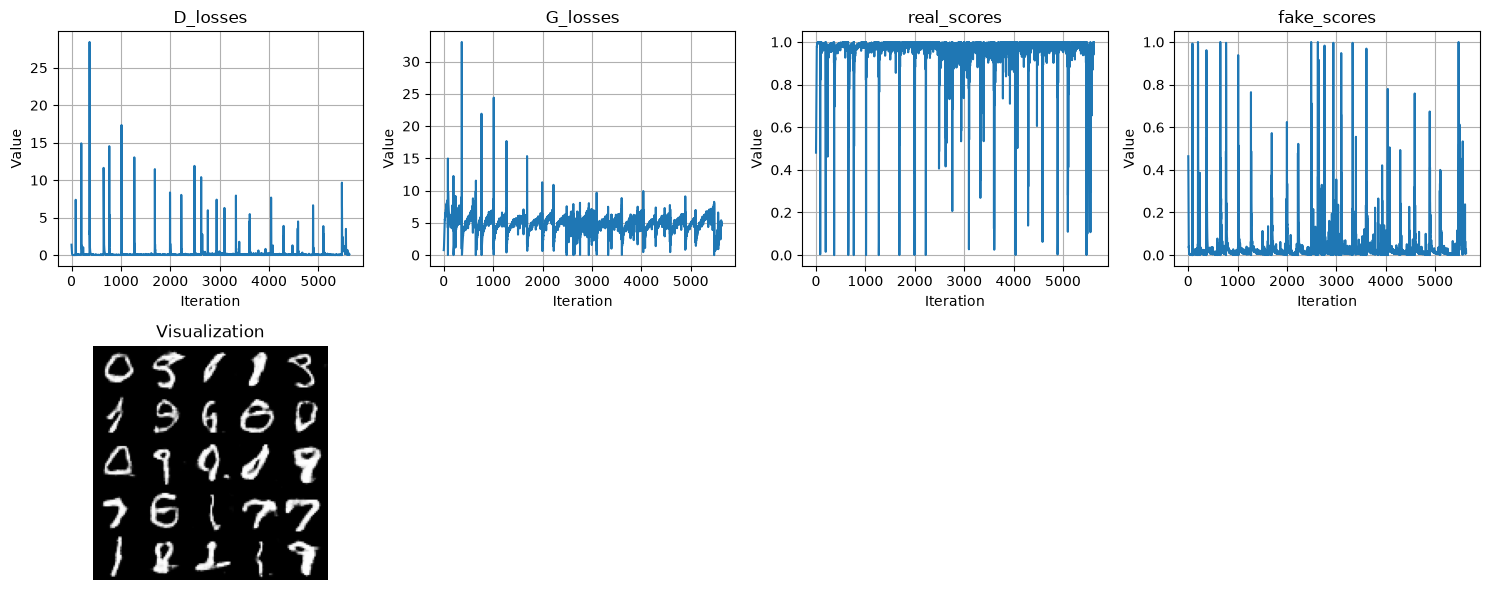

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:17<00:00,  4.76it/s]


Epoch 7/10


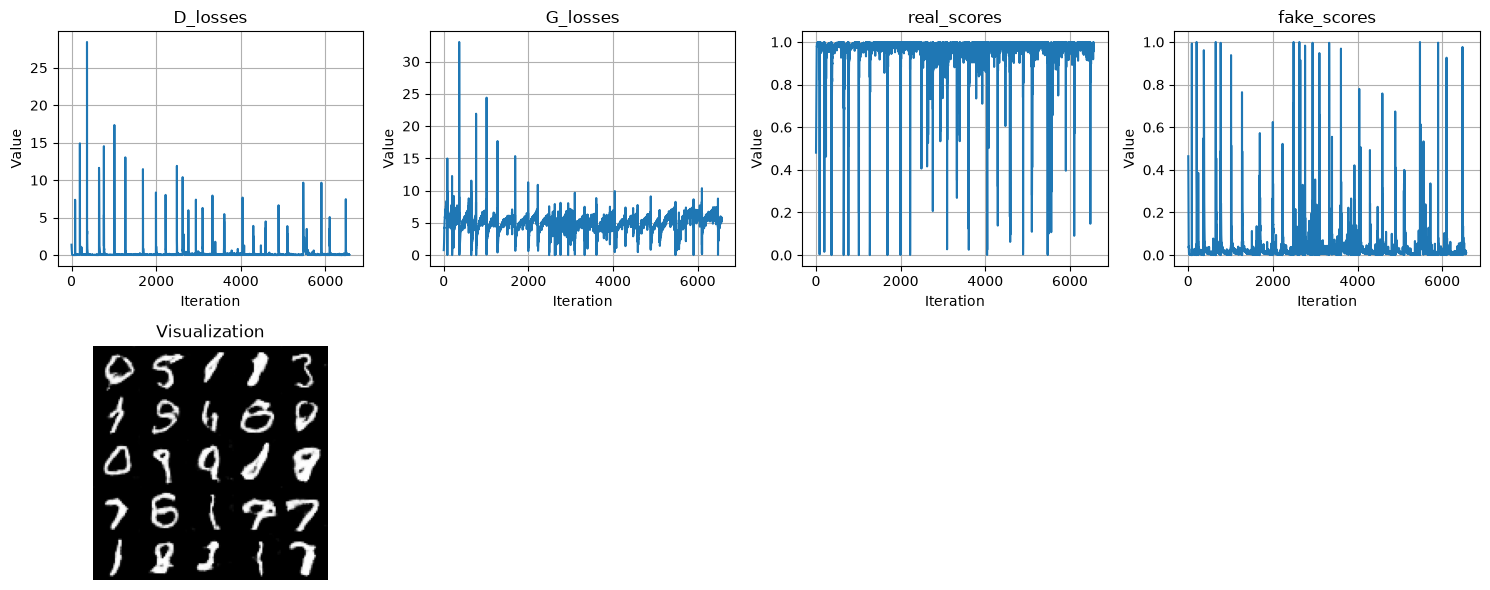

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:19<00:00,  4.69it/s]


Epoch 8/10


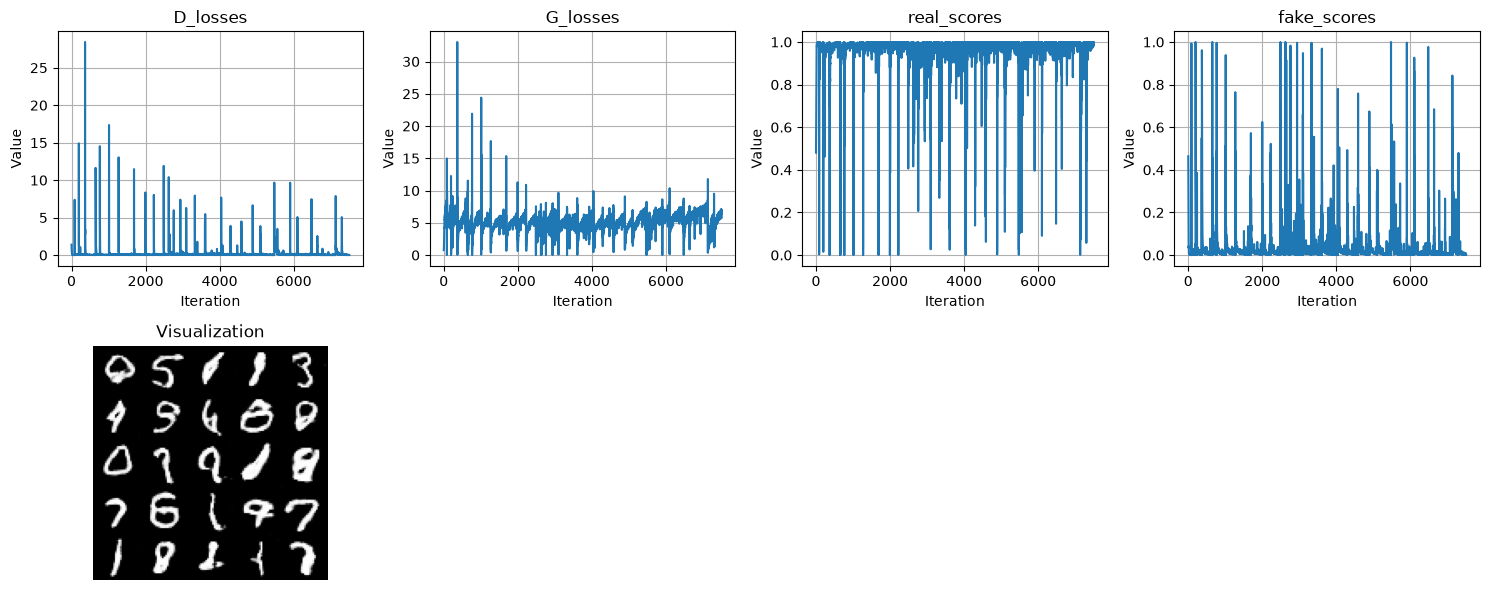

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:28<00:00,  4.50it/s]


Epoch 9/10


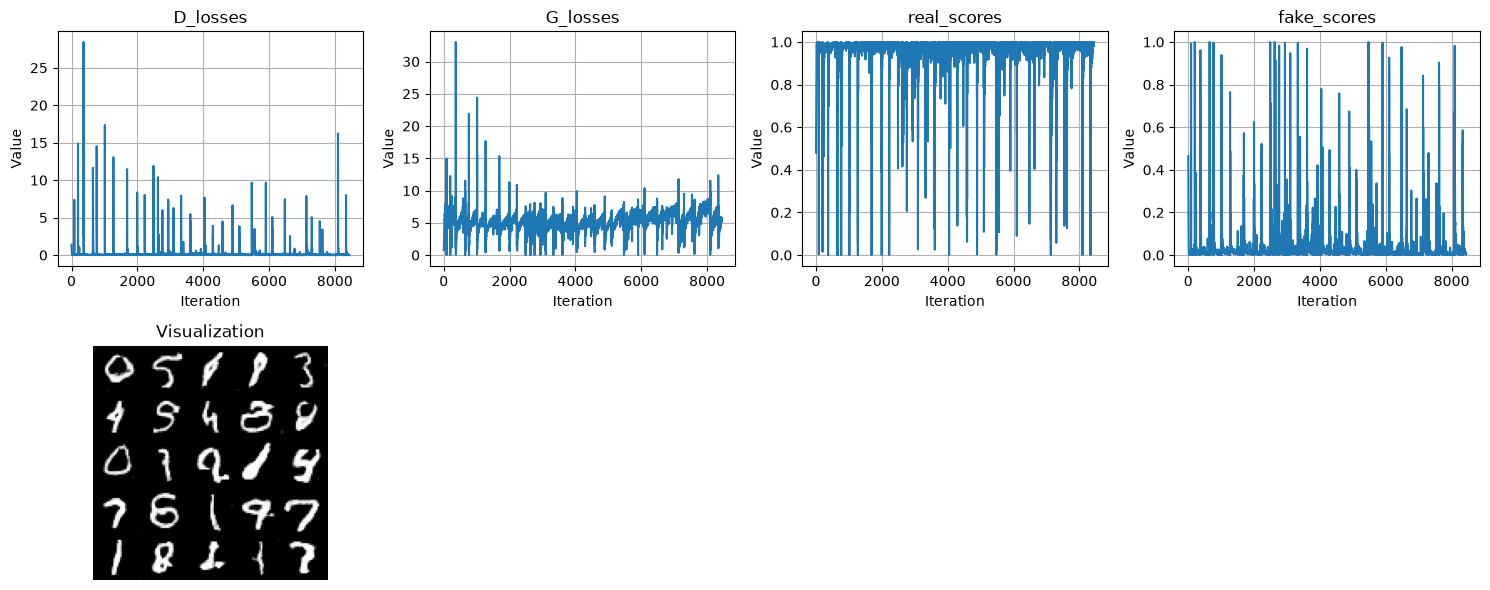

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [03:27<00:00,  4.51it/s]


Epoch 10/10


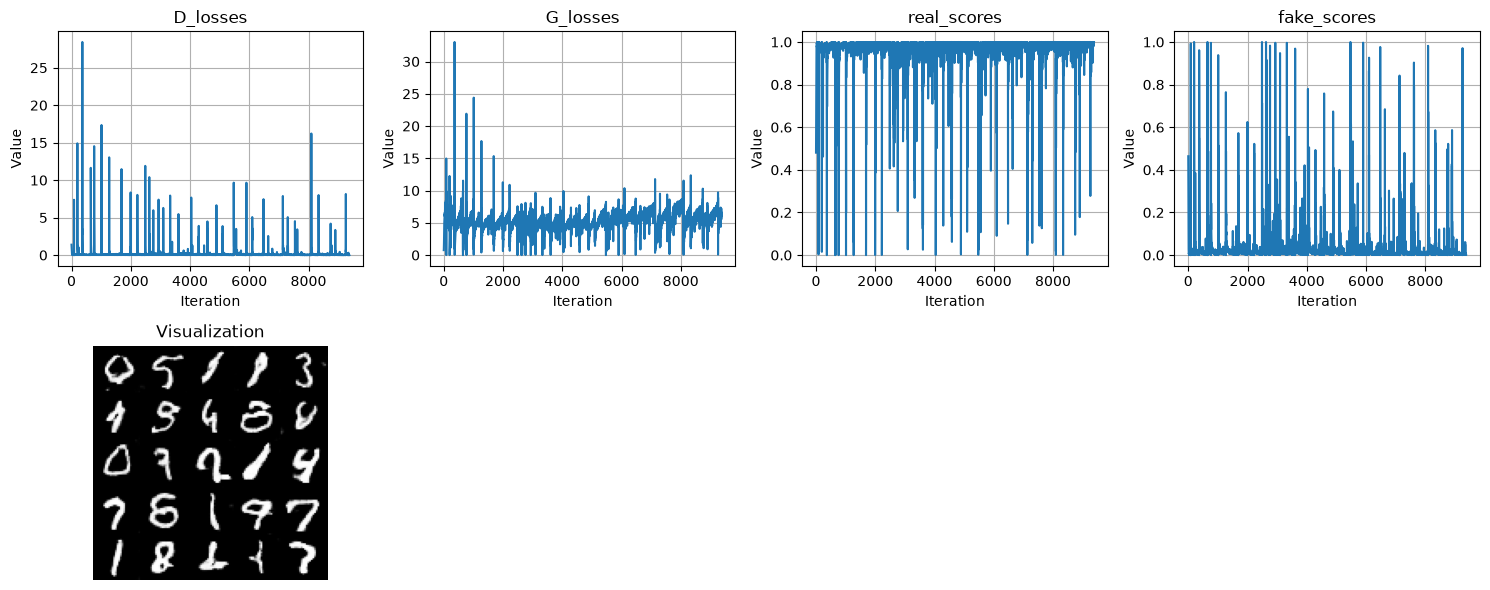

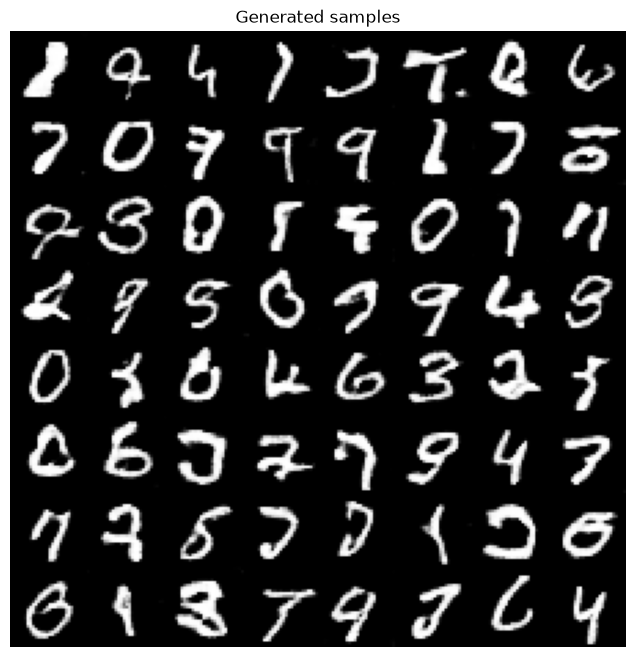

In [29]:
def train_gan(generator, discriminator, train_loader, num_epochs=10,
              latent_dim=128, lr_g=0.0002, lr_d=0.0002, beta1=0.5):
    generator.to(device)
    discriminator.to(device)
    
    generator.apply(weights_init)
    discriminator.apply(weights_init)
    
    # TODO: Set up everything for training
    optimizer_d = optim.Adam(discriminator.parameters(), lr=lr_d, betas=(beta1, 0.999))
    optimizer_g = optim.Adam(generator.parameters(), lr=lr_g, betas=(beta1, 0.999))

    criterion_d = nn.BCELoss()
    criterion_g = nn.BCELoss()

    generator.train()
    discriminator.train()
    
    # Visualization
    visual_metric = {
        'D_losses': [],
        'G_losses': [],
        'real_scores': [],
        'fake_scores': [],
        'images': None
    }
    display_handle = None
    fixed_noise = torch.randn(25, latent_dim, device=device)
    real_label = 1
    fake_label = 0
    
    print("Starting Training...")
    for epoch in range(num_epochs):
        for i, (real_images, _) in enumerate(tqdm(train_loader)):
            real_images = real_images.to(device)
            batch_size = real_images.size(0)
            # TODO: Train Discriminator
            # You will need to compute discriminator loss for real and fake images
            discriminator.requires_grad_(True)
            optimizer_d.zero_grad()
            output_real = discriminator(real_images)
            d_loss_real = criterion_d(output_real, torch.ones_like(output_real))

            noise = torch.randn(batch_size, latent_dim, device=device)
            fake_images = generator(noise)
            output_fake = discriminator(fake_images.detach())
            d_loss_fake = criterion_d(output_fake, torch.zeros_like(output_fake))
            
            d_loss = d_loss_real + d_loss_fake
            d_loss.backward()
            optimizer_d.step()
            
            optimizer_g.zero_grad()
            discriminator.requires_grad_(False)

            generated_pred = discriminator(fake_images)
            g_loss = criterion_g(generated_pred, torch.ones_like(generated_pred))

            g_loss.backward()
            optimizer_g.step()
            
            # Visualization
            visual_metric['D_losses'].append(d_loss.item())
            visual_metric['G_losses'].append(g_loss.item())
            visual_metric['real_scores'].append(output_real.mean().item())
            visual_metric['fake_scores'].append(generated_pred.detach().mean().item())
            if i % 50 == 0:
                generator.eval()
                with torch.no_grad():
                    preview = generator(fixed_noise).cpu()
                generator.train()
                
                preview = (preview + 1) / 2
                preview = (
                    preview.reshape(5, 5, 1, 28, 28)
                    .permute(2, 0, 3, 1, 4)
                    .reshape(140, 140)
                )
                visual_metric['images'] = (preview.clamp(0, 1).unsqueeze(-1).repeat(1, 1, 3).numpy())
                
                display_handle = visualize_progress(visual_metric, display_handle, display_id='gan')

        # Epoch vis
        generator.eval()
        with torch.no_grad():
            preview = generator(fixed_noise).cpu()
        generator.train()

        preview = ((preview + 1) / 2).clamp(0, 1)
        preview = (preview.reshape(5, 5, 1, 28, 28).permute(2, 0, 3, 1, 4).reshape(140, 140))
        visual_metric['images'] = (preview.unsqueeze(-1).repeat(1, 1, 3).numpy())

        display_handle = visualize_progress(visual_metric, display_handle, display_id='gan')
        print(f"Epoch {epoch + 1}/{num_epochs}")
        visualize_progress(visual_metric, display_handle=None, display_id=True)

    test_noise = torch.randn(64, latent_dim, device=device)
    generator.eval()
    test_noise = torch.randn(64, latent_dim, device=device)

    with torch.no_grad():
        samples = generator(test_noise).cpu()

    samples = (samples + 1) / 2
    grid = (samples.reshape(8, 8, 1, 28, 28).permute(2, 0, 3, 1, 4).reshape(8 * 28, 8 * 28))
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.numpy(), cmap='gray', vmin=0, vmax=1)
    plt.axis('off')
    plt.title("Generated samples")
    plt.show()

generator = Generator(latent_dim=128)
discriminator = Discriminator()
train_loader, val_loader, test_loader = load_mnist(batch_size=64, val_split=0.)
train_gan(generator, discriminator, train_loader)

## Wasserstein GAN Implementation

Implemented a Wasserstein GAN (WGAN) using the MNIST dataset using the Wasserstein distance instead of the Jensen-Shannon divergence. Lipschitz constraint enforced using weight clipping.


In [31]:
class Critic(nn.Module):
    def __init__(self):
        super(Critic, self).__init__()
        self.model = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.model(x)

In [38]:
def train_wgan(generator, discriminator, train_loader, num_epochs=10,
               latent_dim=128, lr_g=0.00005, lr_d=0.00005,
               n_critic=5, clip_value=0.01):
    generator.to(device)
    discriminator.to(device)

    # generator.apply(weights_init)     Ran 20 more epochs later
    # discriminator.apply(weights_init)

    optimizer_d = optim.RMSprop(discriminator.parameters(), lr=lr_d)
    optimizer_g = optim.RMSprop(generator.parameters(), lr=lr_g)

    generator.train()
    discriminator.train()
    
    # Visualization
    visual_metric = {
        'Wasserstein_estimate': [],
        'G_losses': [],
        'real_scores': [],
        'fake_scores': [],
        'images': None
    }
    display_handle = None
    fixed_noise = torch.randn(25, latent_dim, device=device)
    critic_steps = 0

    print("Starting Training...")
    for epoch in range(num_epochs):
        for i, (real_images, _) in enumerate(tqdm(train_loader)):
            real_images = real_images.to(device)
            batch_size = real_images.size(0)

            discriminator.requires_grad_(True)
            optimizer_d.zero_grad()
            output_real = discriminator(real_images)

            noise = torch.randn(batch_size, latent_dim, device=device)

            with torch.no_grad():
                fake_images = generator(noise) # Might not update generator
            output_fake = discriminator(fake_images.detach())

            d_loss = output_fake.mean() - output_real.mean()
            d_loss.backward()
            optimizer_d.step()

            with torch.no_grad():
                for p in discriminator.parameters():
                    p.clamp_(-clip_value, clip_value)

            critic_steps += 1
            
            if critic_steps % n_critic == 0:
                optimizer_g.zero_grad()
                discriminator.requires_grad_(False)

                noise = torch.randn(batch_size, latent_dim, device=device)
                fake_images = generator(noise)
                generated_pred = discriminator(fake_images)

                g_loss = -generated_pred.mean()
                g_loss.backward()
                optimizer_g.step()

                visual_metric['Wasserstein_estimate'].append(-d_loss.item())
                visual_metric['G_losses'].append(g_loss.item())
                visual_metric['real_scores'].append(output_real.mean().item())
                visual_metric['fake_scores'].append(
                    generated_pred.detach().mean().item()
                )

            # Visualization
            if i % 50 == 0:
                generator.eval()
                with torch.no_grad():
                    preview = generator(fixed_noise).cpu()
                generator.train()

                preview = (preview + 1) / 2
                preview = (
                    preview.reshape(5, 5, 1, 28, 28)
                    .permute(2, 0, 3, 1, 4)
                    .reshape(140, 140)
                )
                visual_metric['images'] = (
                    preview.clamp(0, 1).unsqueeze(-1).repeat(1, 1, 3).numpy()
                )

                display_handle = visualize_progress(
                    visual_metric, display_handle, display_id='wgan'  # WGAN: separate display
                )

        # Epoch vis
        generator.eval()
        with torch.no_grad():
            preview = generator(fixed_noise).cpu()
        generator.train()

        preview = ((preview + 1) / 2).clamp(0, 1)
        preview = (
            preview.reshape(5, 5, 1, 28, 28)
            .permute(2, 0, 3, 1, 4)
            .reshape(140, 140)
        )
        visual_metric['images'] = (
            preview.unsqueeze(-1).repeat(1, 1, 3).numpy()
        )

        display_handle = visualize_progress(
            visual_metric, display_handle, display_id='wgan'  # WGAN: separate display
        )
        print(f"Epoch {epoch + 1}/{num_epochs}")
        visualize_progress(visual_metric, display_handle=None, display_id=True)

    test_noise = torch.randn(64, latent_dim, device=device)
    generator.eval()
    test_noise = torch.randn(64, latent_dim, device=device)

    with torch.no_grad():
        samples = generator(test_noise).cpu()

    samples = (samples + 1) / 2
    grid = (
        samples.reshape(8, 8, 1, 28, 28)
        .permute(2, 0, 3, 1, 4)
        .reshape(8 * 28, 8 * 28)
    )
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.numpy(), cmap='gray', vmin=0, vmax=1)
    plt.axis('off')
    plt.title("Generated samples")
    plt.show()
    

Starting Training...


  0%|                                                                                                                                                                           | 0/938 [00:00<?, ?it/s]

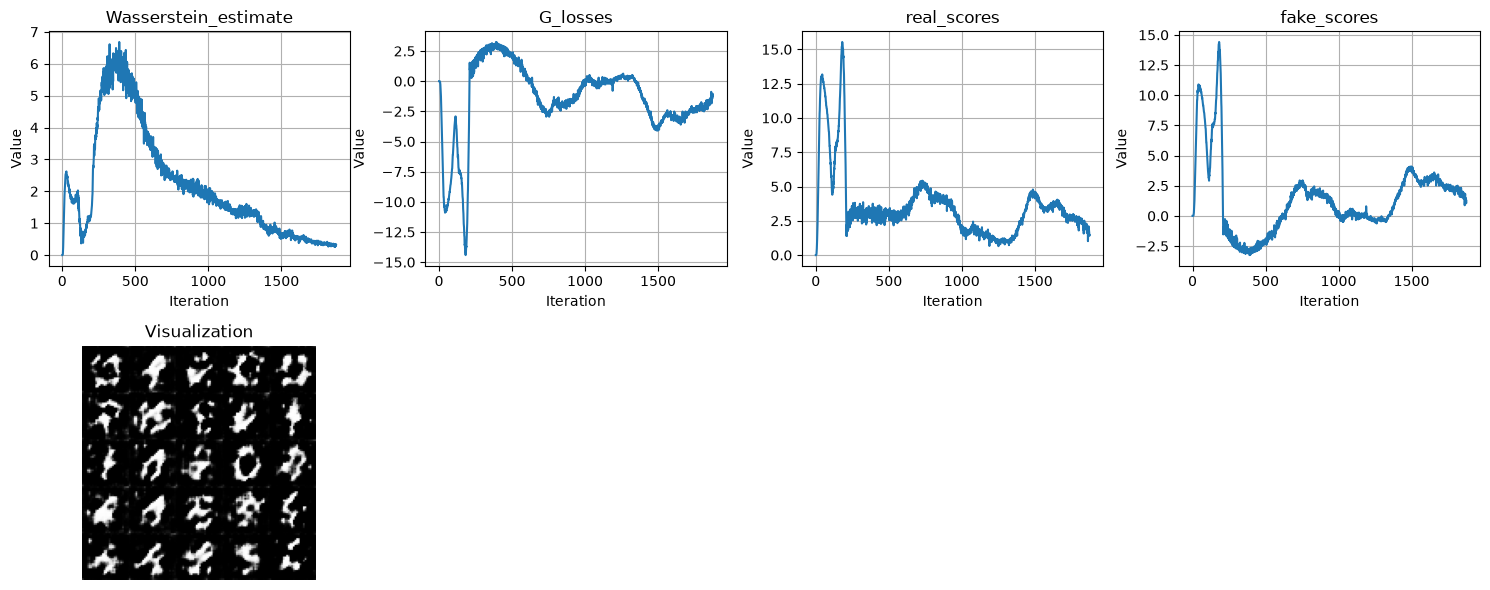

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:34<00:00,  6.09it/s]


Epoch 1/10


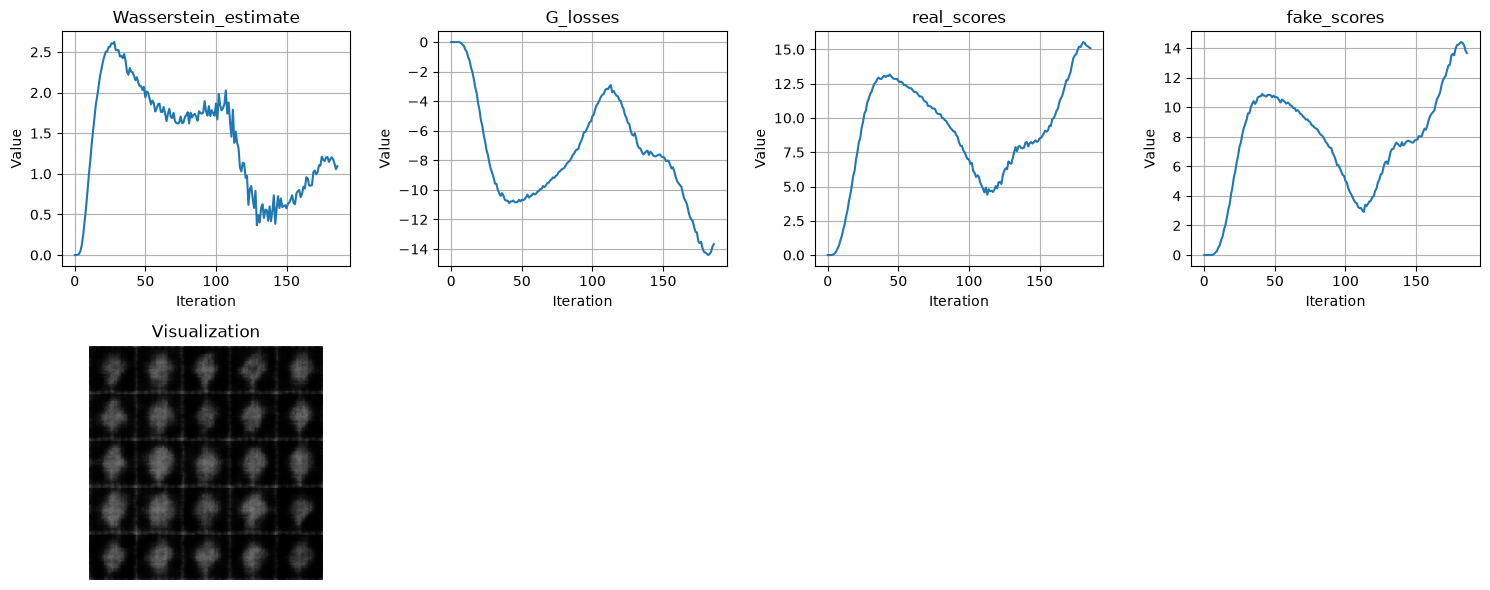

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:32<00:00,  6.14it/s]


Epoch 2/10


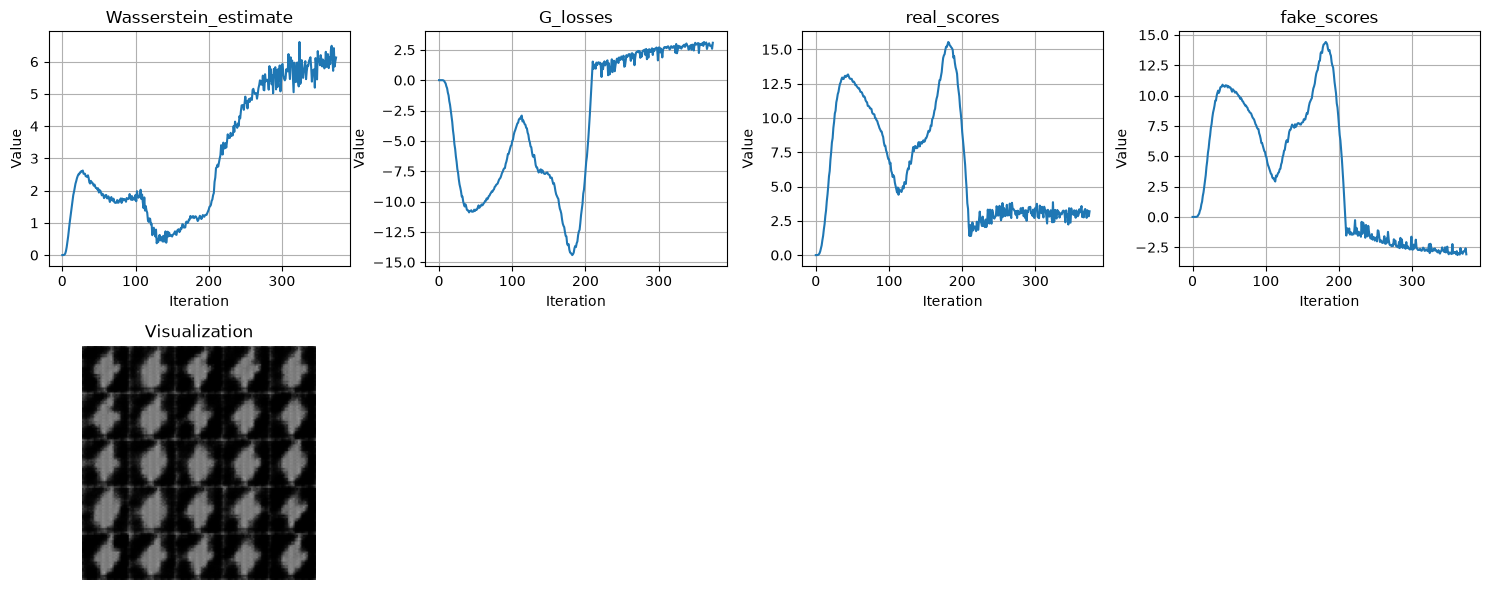

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:26<00:00,  6.41it/s]


Epoch 3/10


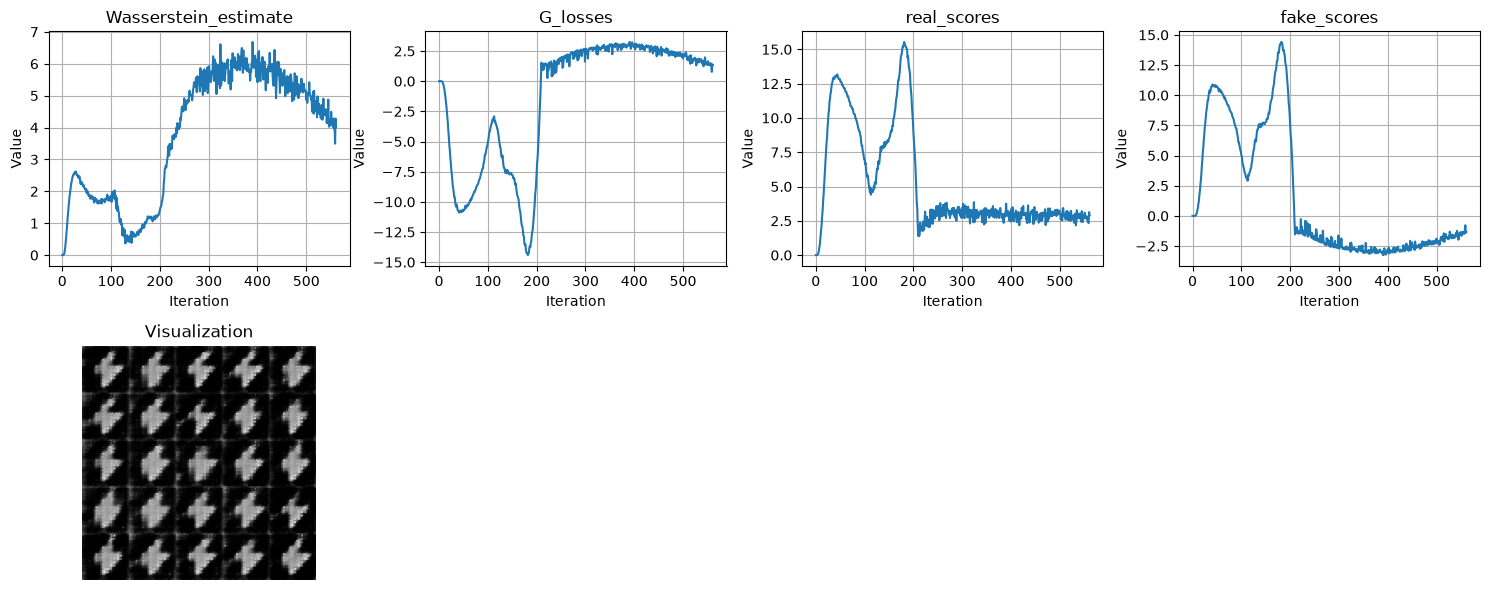

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:28<00:00,  6.33it/s]


Epoch 4/10


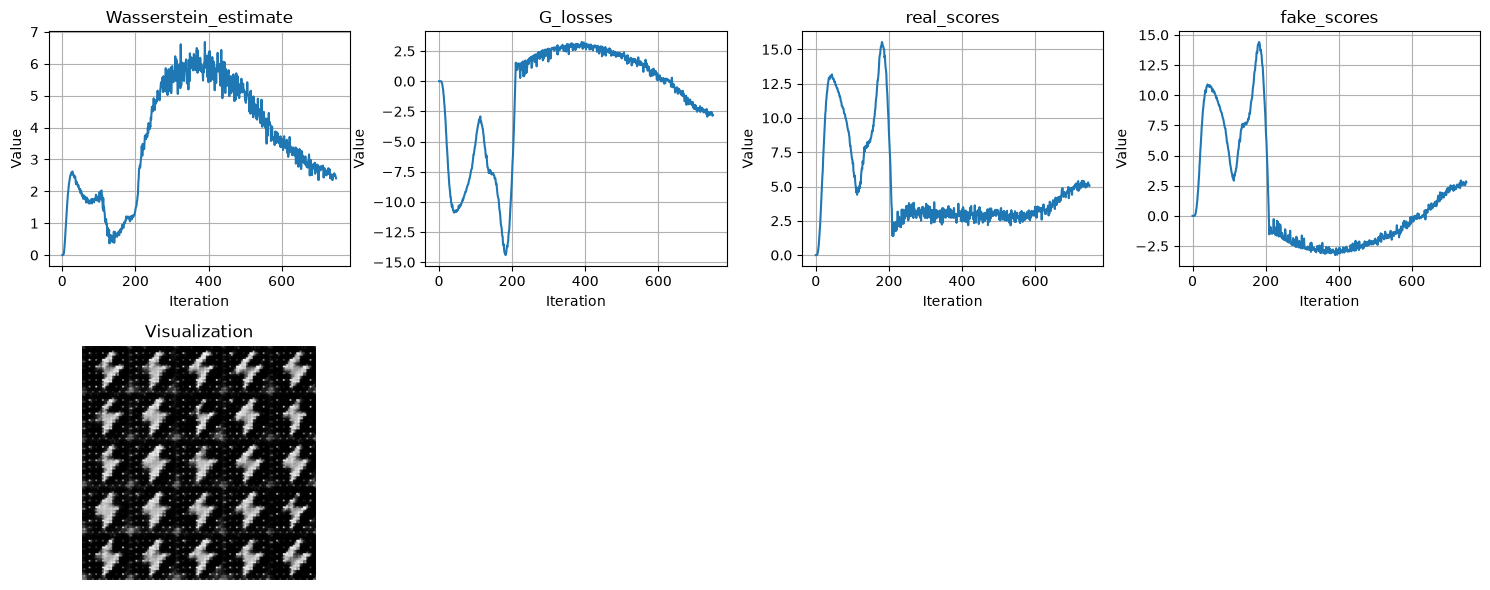

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:24<00:00,  6.50it/s]


Epoch 5/10


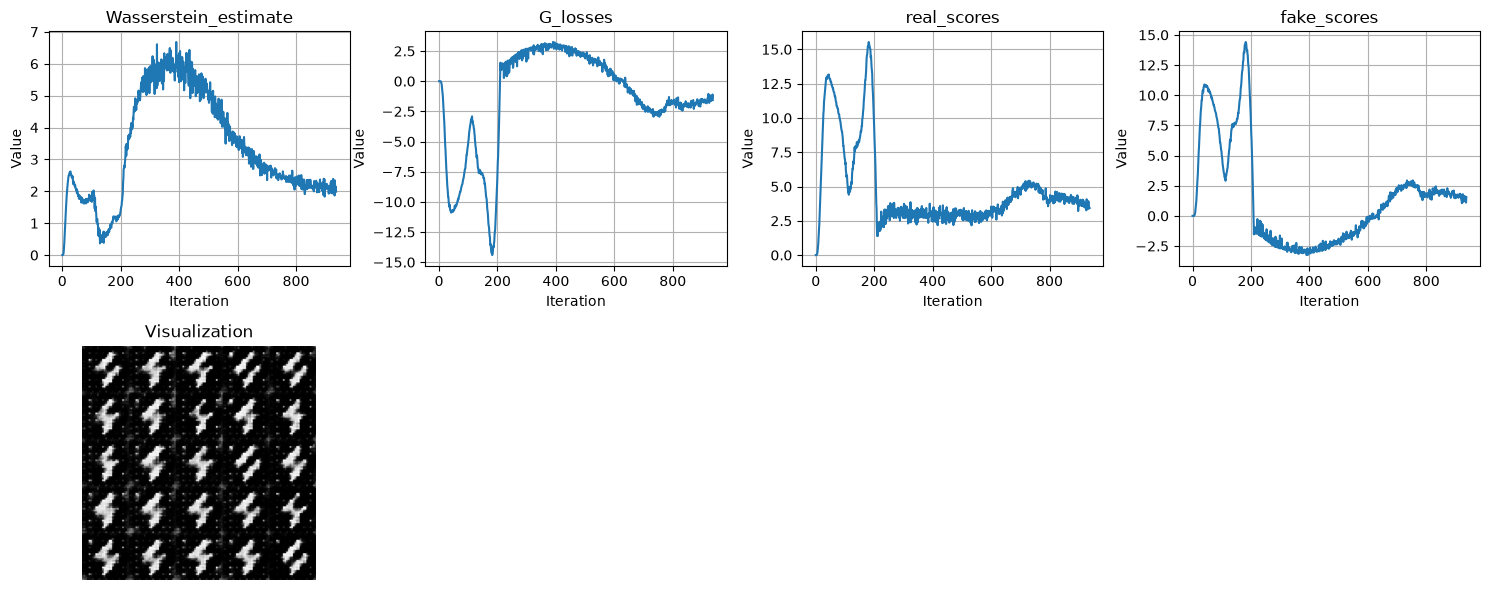

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:09<00:00,  7.26it/s]


Epoch 6/10


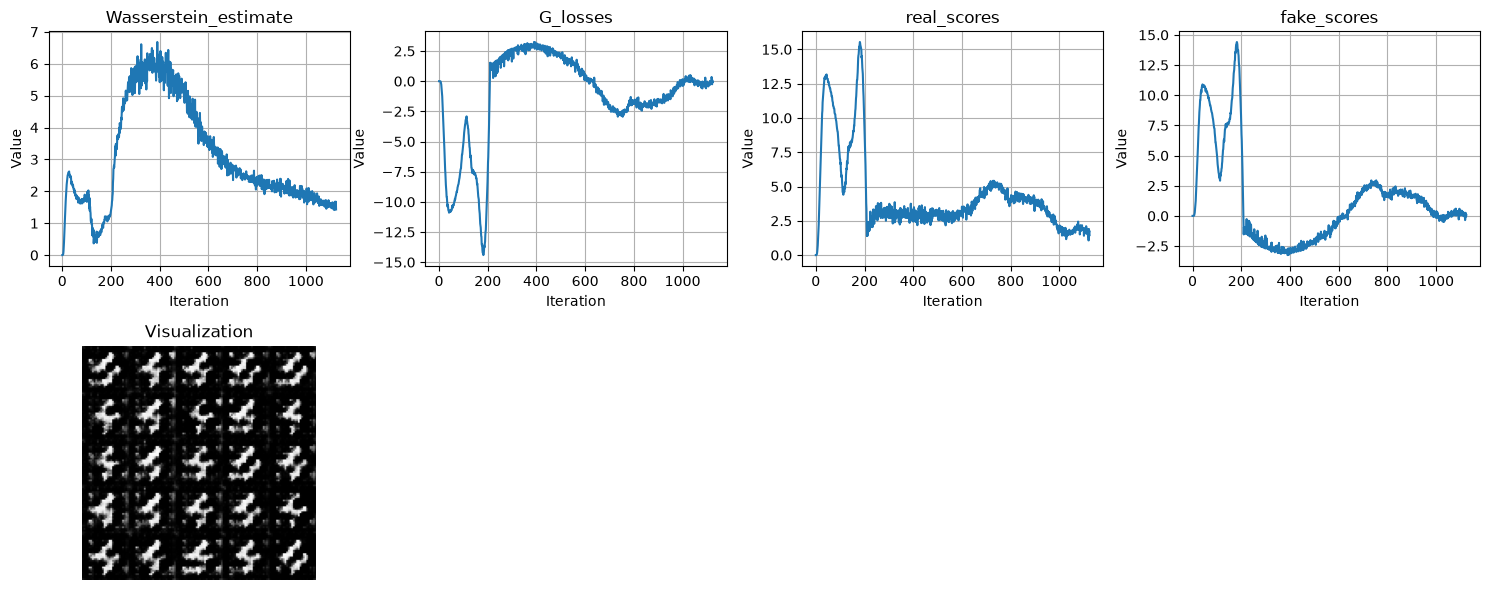

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:17<00:00,  6.80it/s]


Epoch 7/10


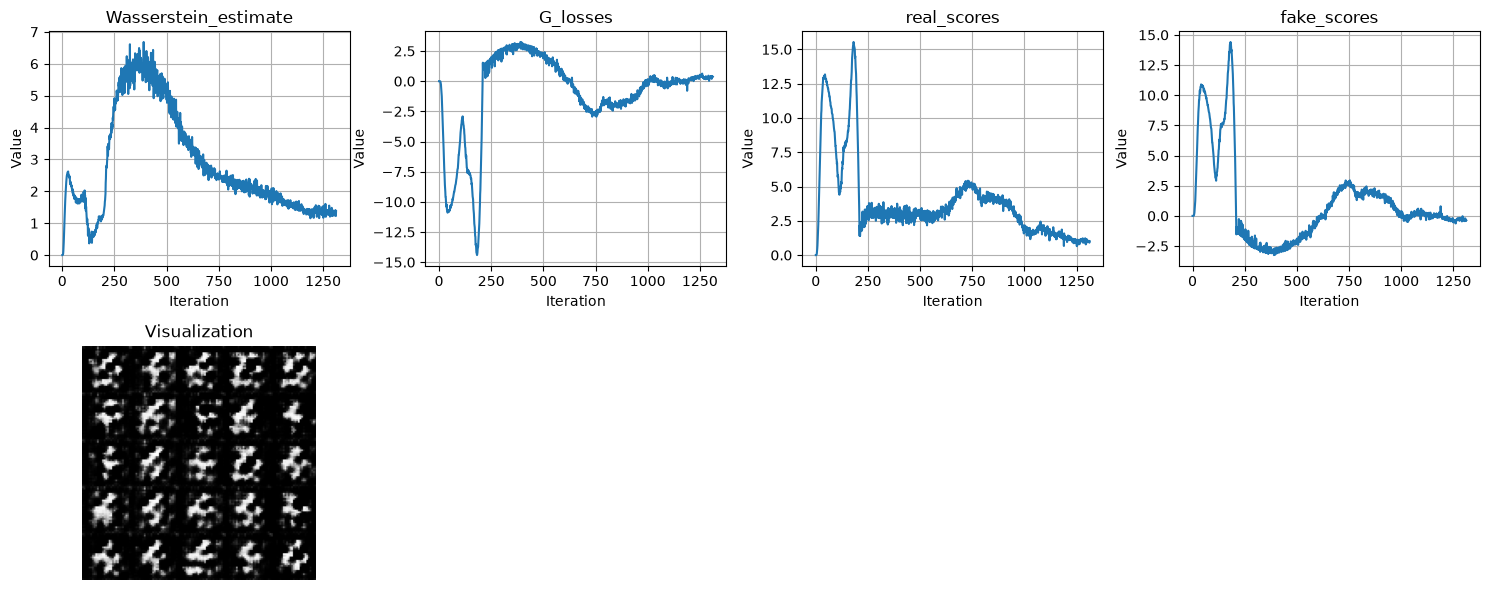

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:22<00:00,  6.56it/s]


Epoch 8/10


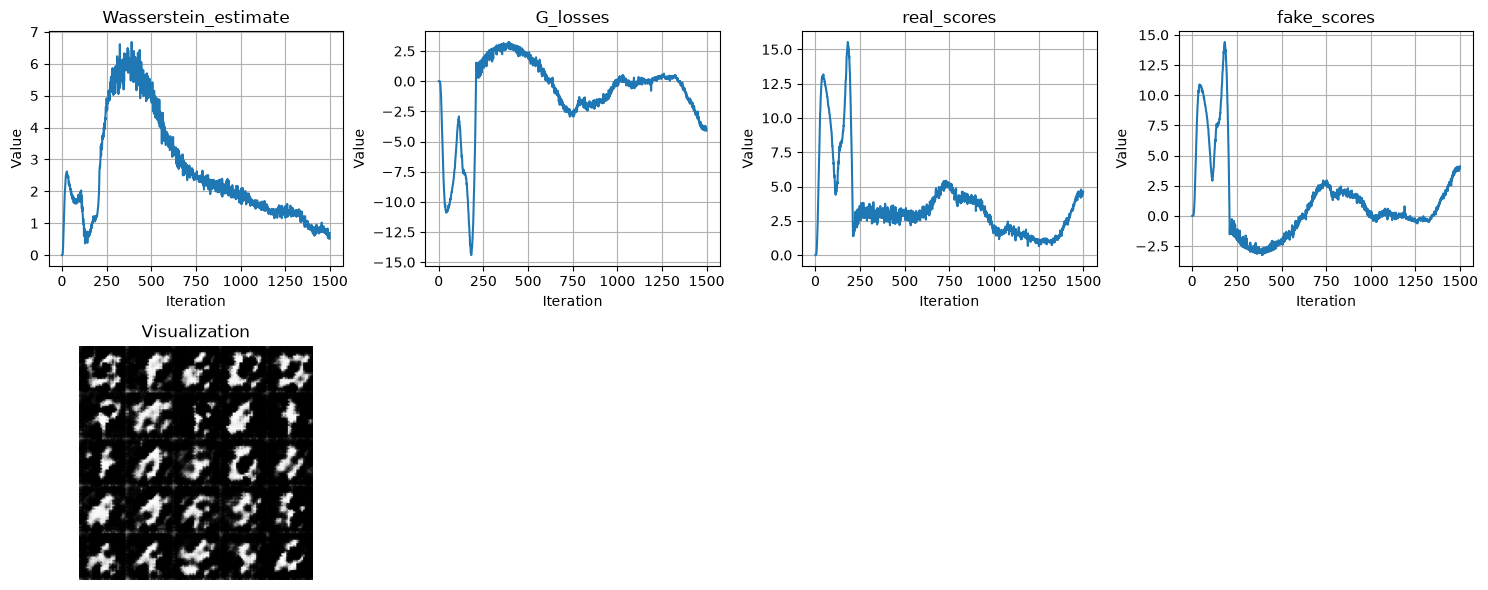

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:20<00:00,  6.69it/s]


Epoch 9/10


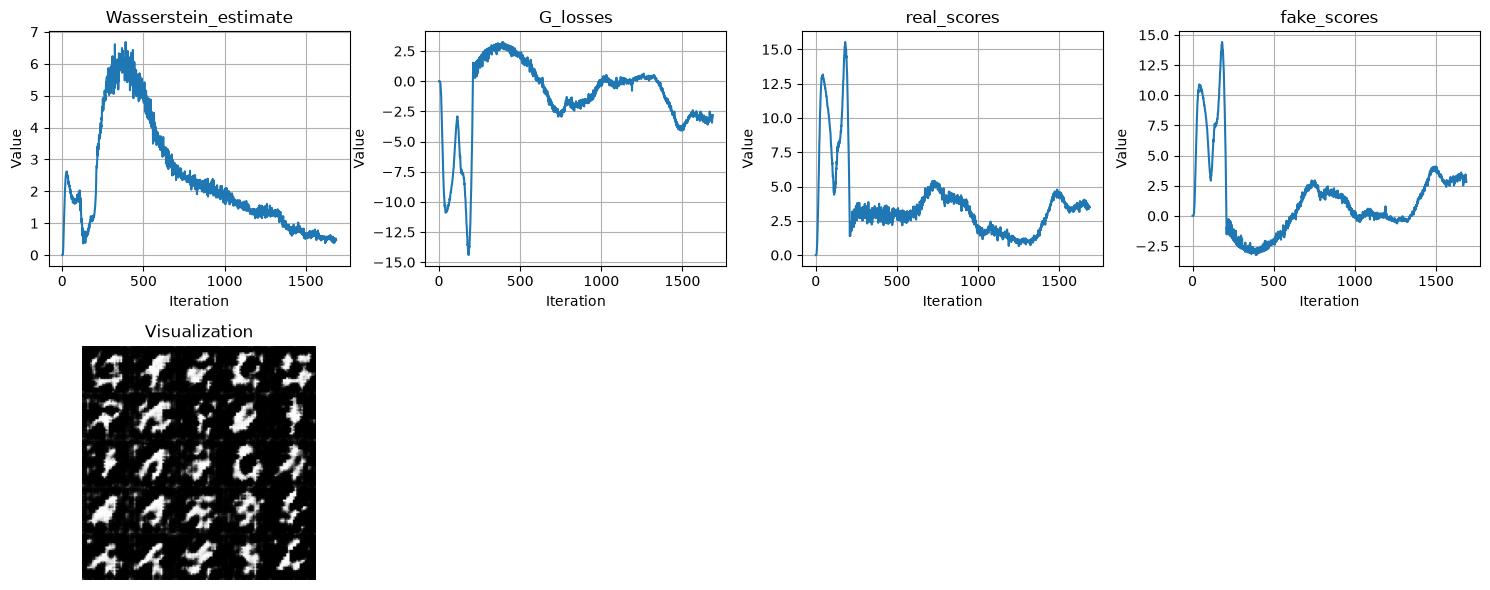

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:20<00:00,  6.68it/s]


Epoch 10/10


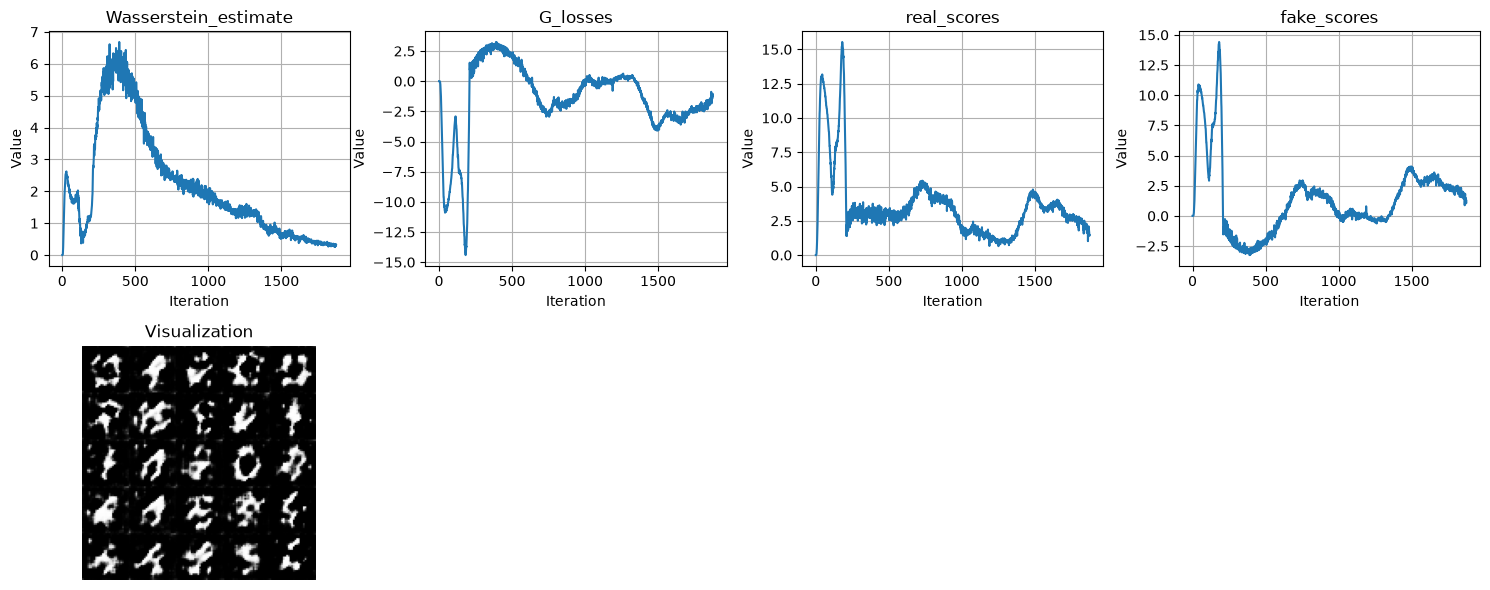

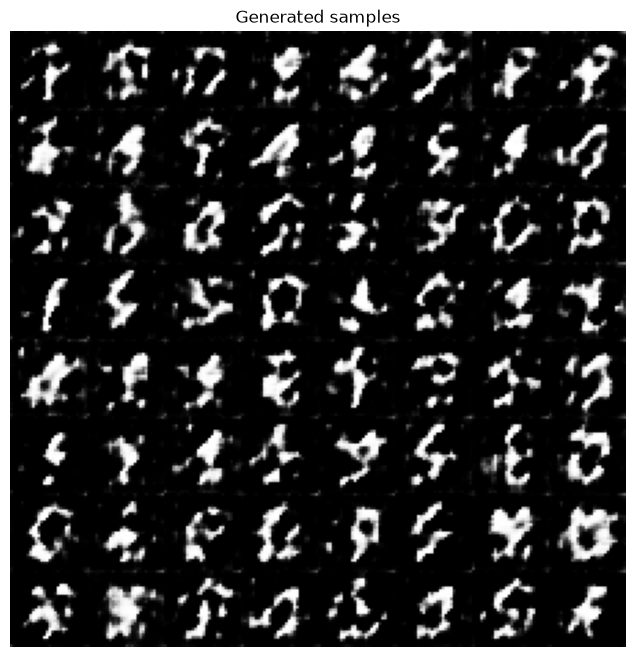

In [32]:
wgan_generator = Generator(latent_dim=128)
critic = Critic()
train_loader, val_loader, test_loader = load_mnist(batch_size=64, val_split=0.)

train_wgan(wgan_generator, critic, train_loader)

Starting Training...


  0%|                                                                                                                                                                           | 0/938 [00:00<?, ?it/s]

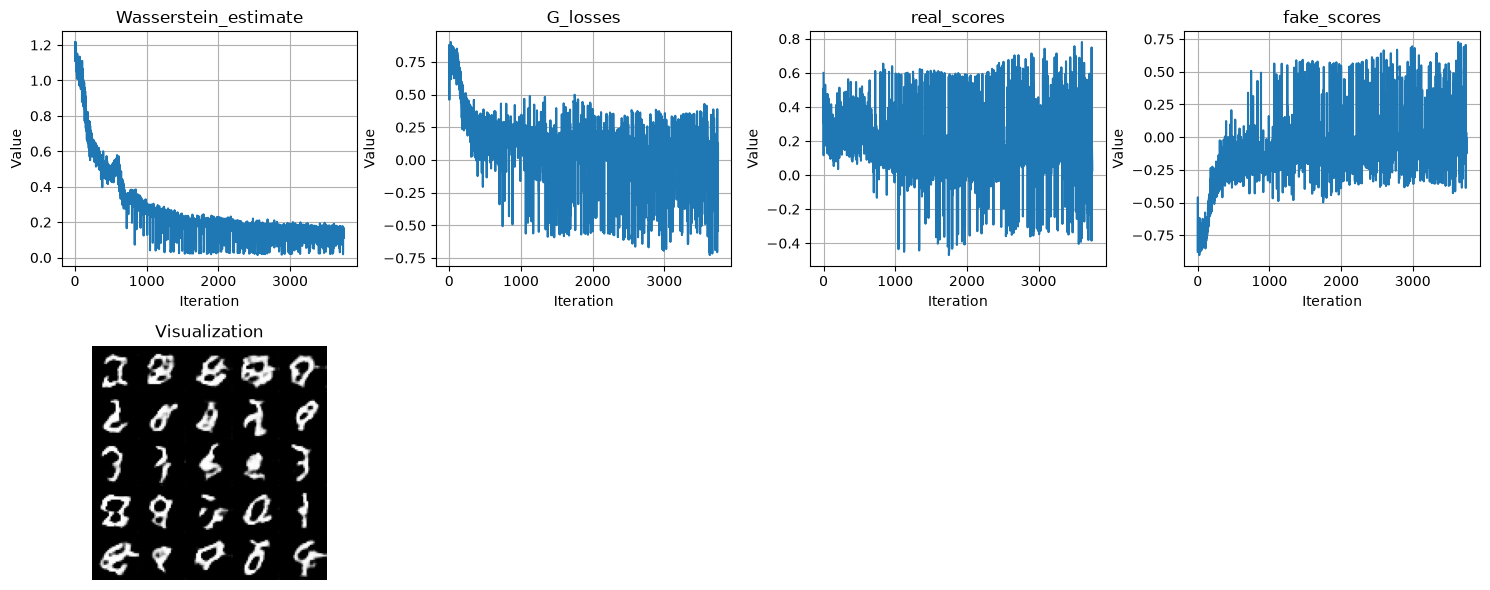

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:22<00:00,  6.60it/s]


Epoch 1/20


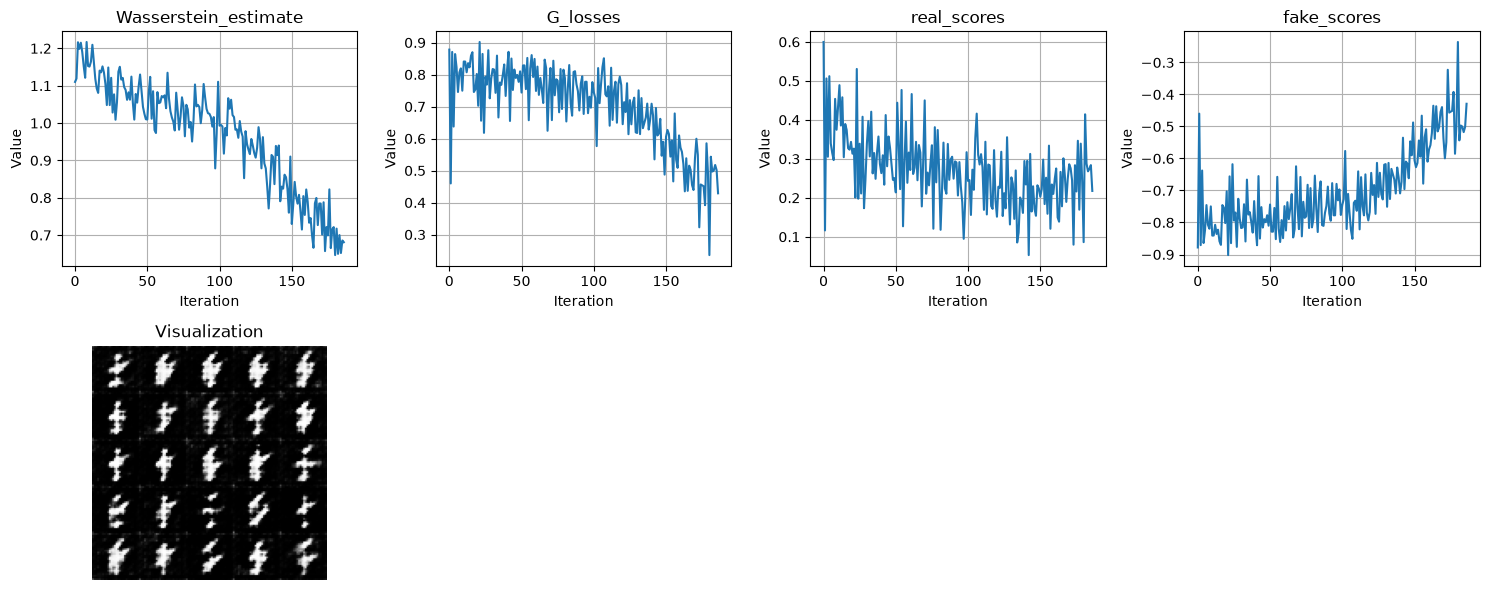

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:21<00:00,  6.63it/s]


Epoch 2/20


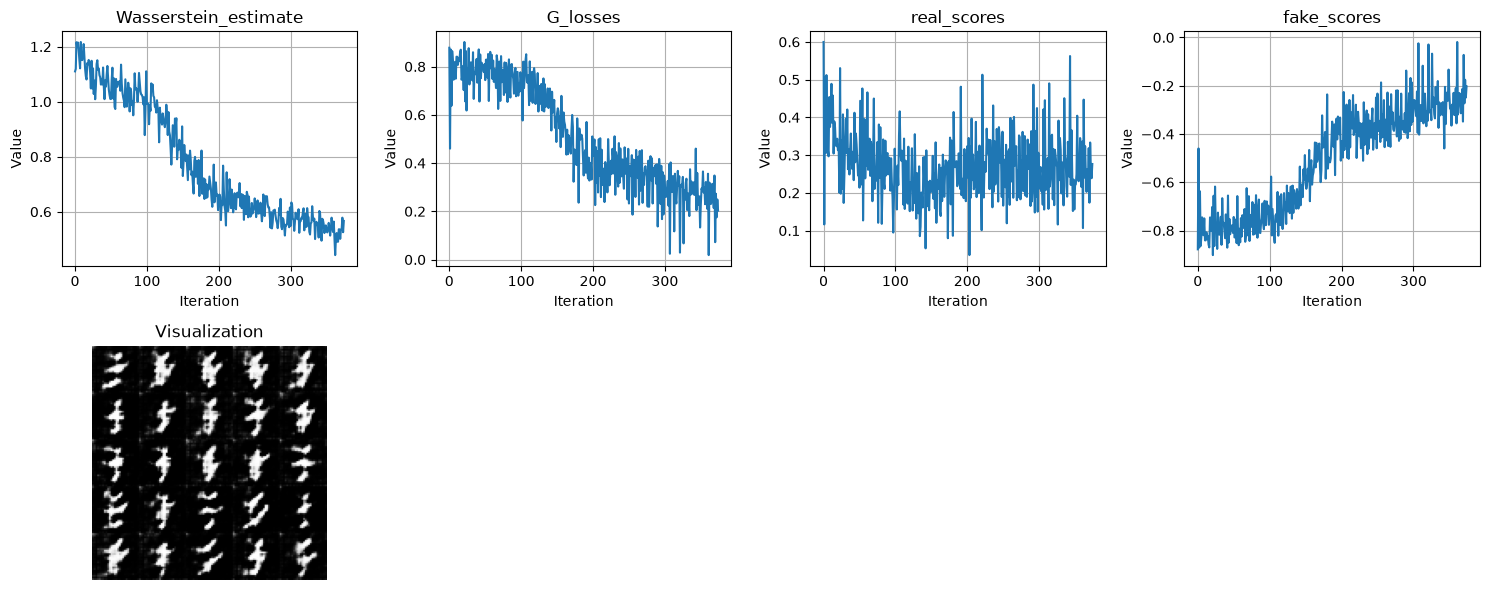

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:21<00:00,  6.62it/s]


Epoch 3/20


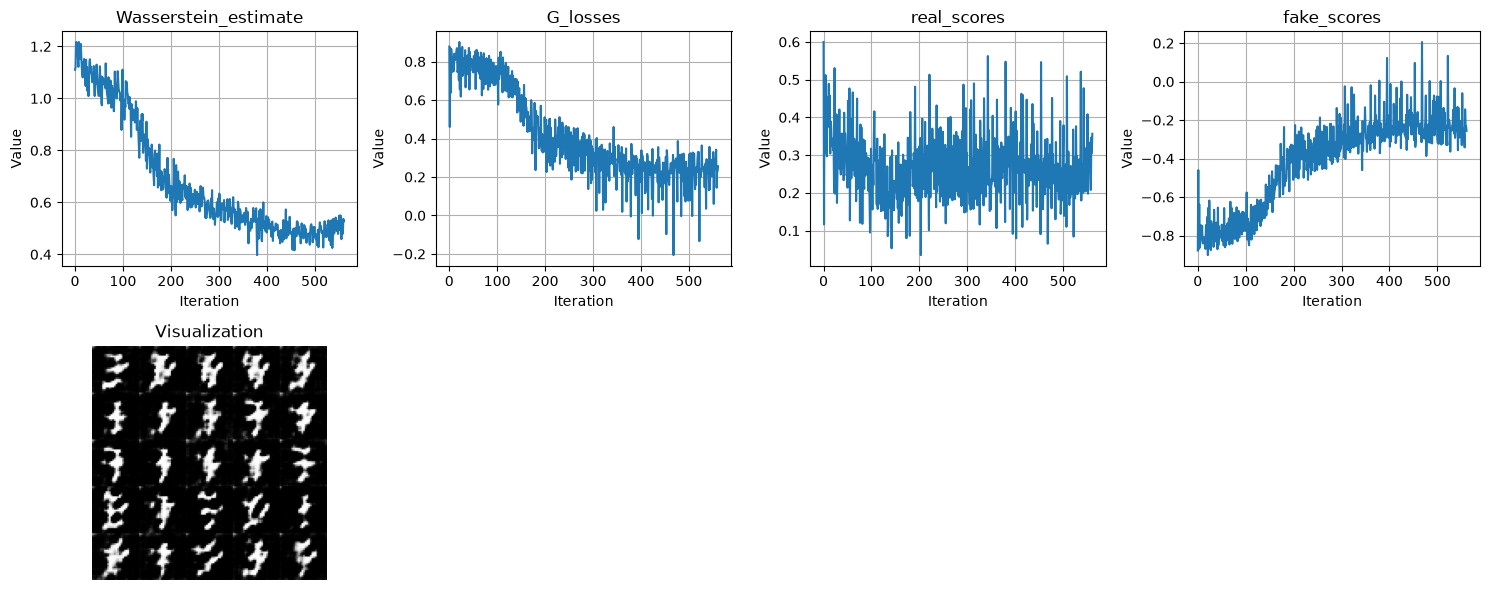

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:25<00:00,  6.44it/s]


Epoch 4/20


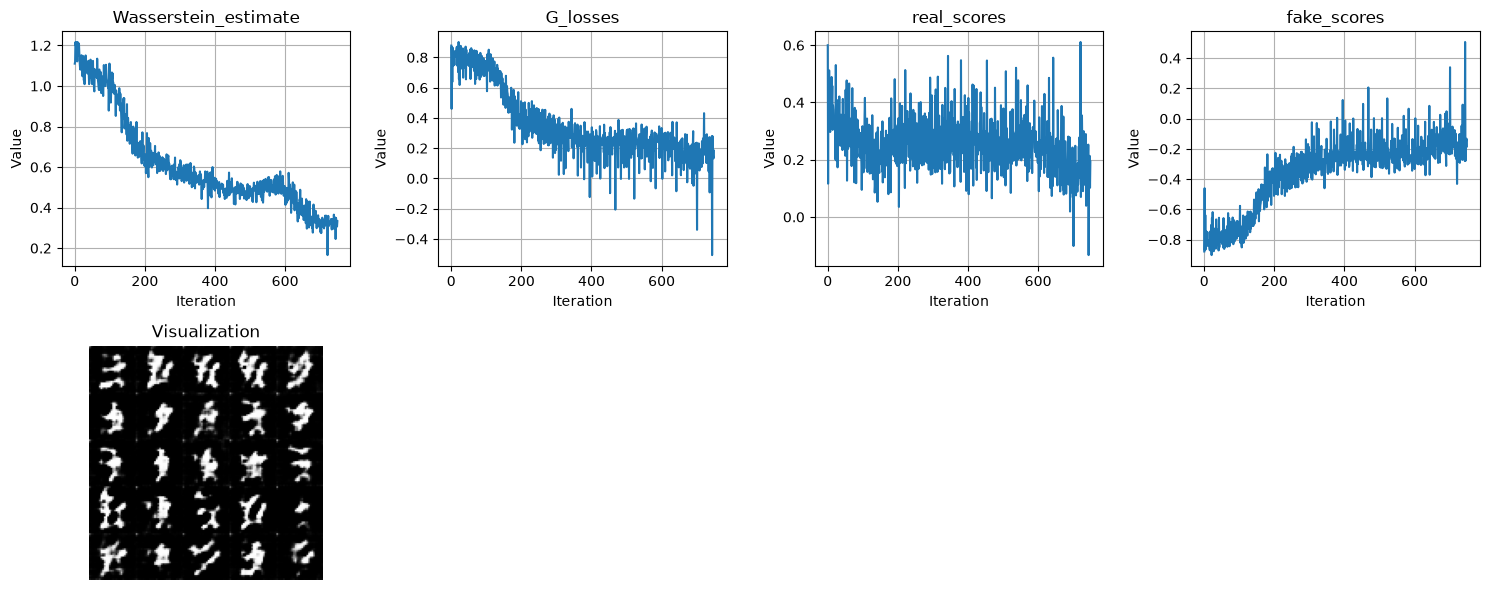

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:27<00:00,  6.38it/s]


Epoch 5/20


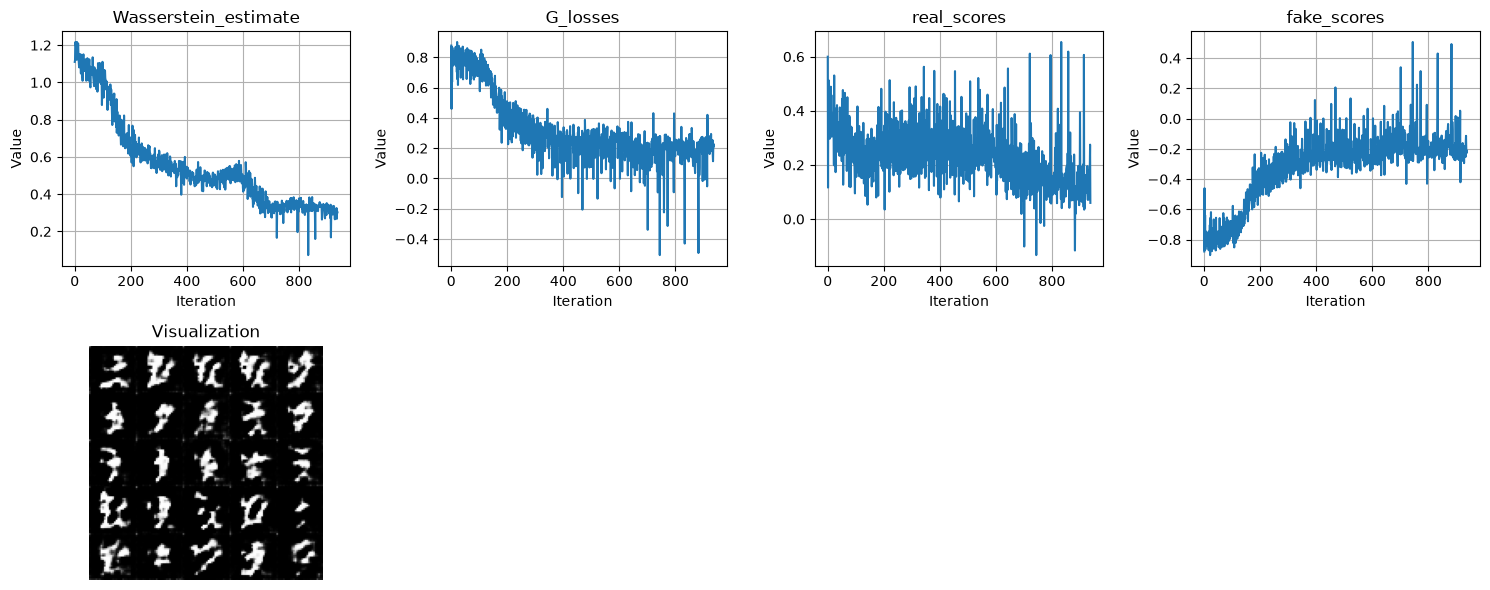

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:24<00:00,  6.51it/s]


Epoch 6/20


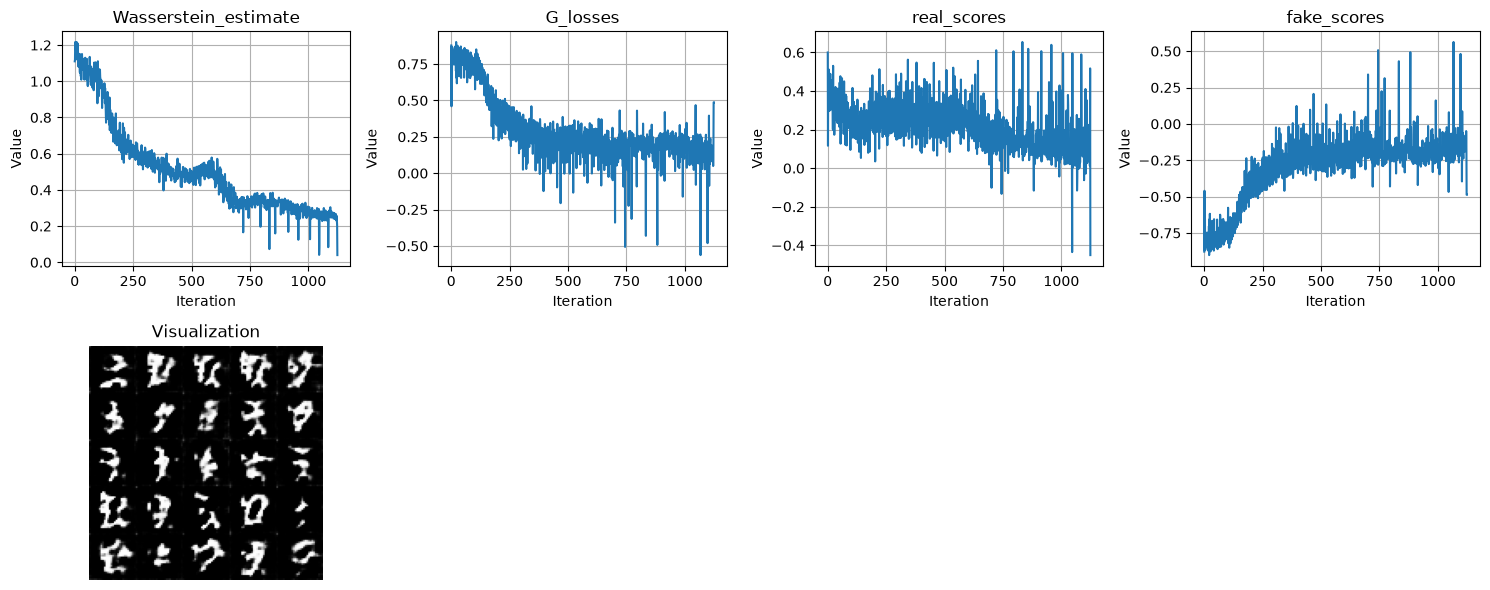

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:23<00:00,  6.55it/s]


Epoch 7/20


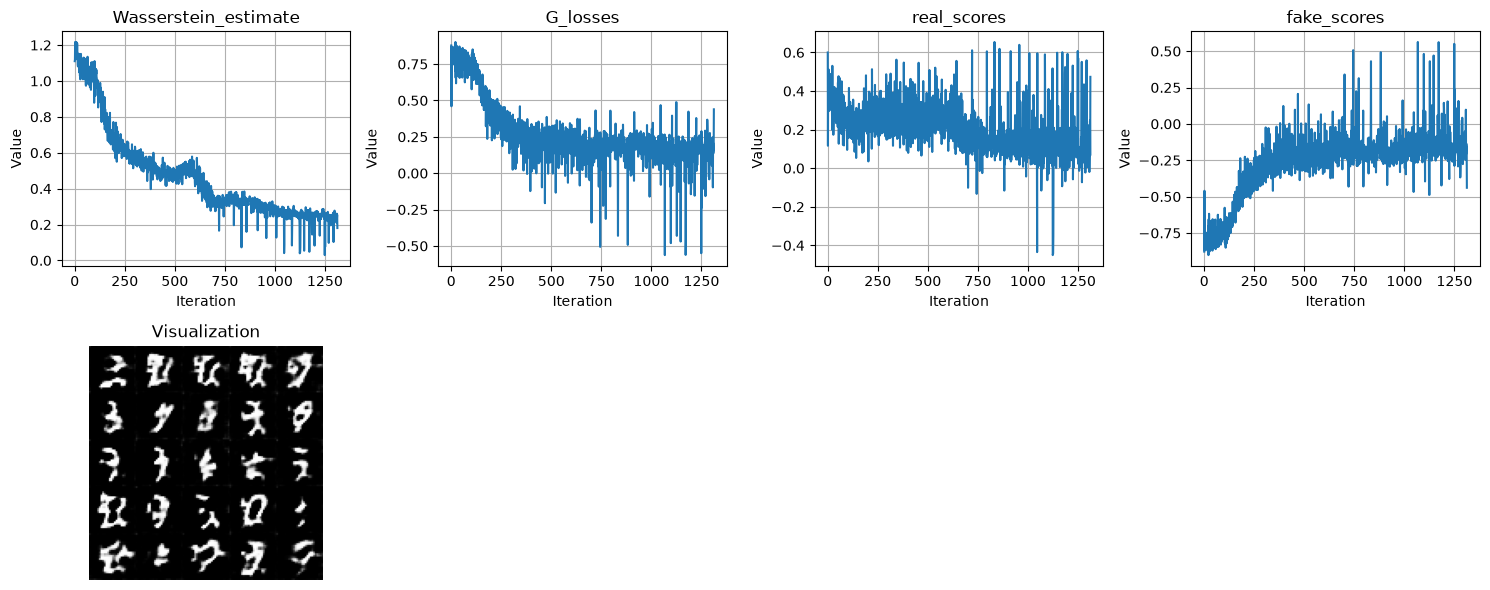

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:24<00:00,  6.51it/s]


Epoch 8/20


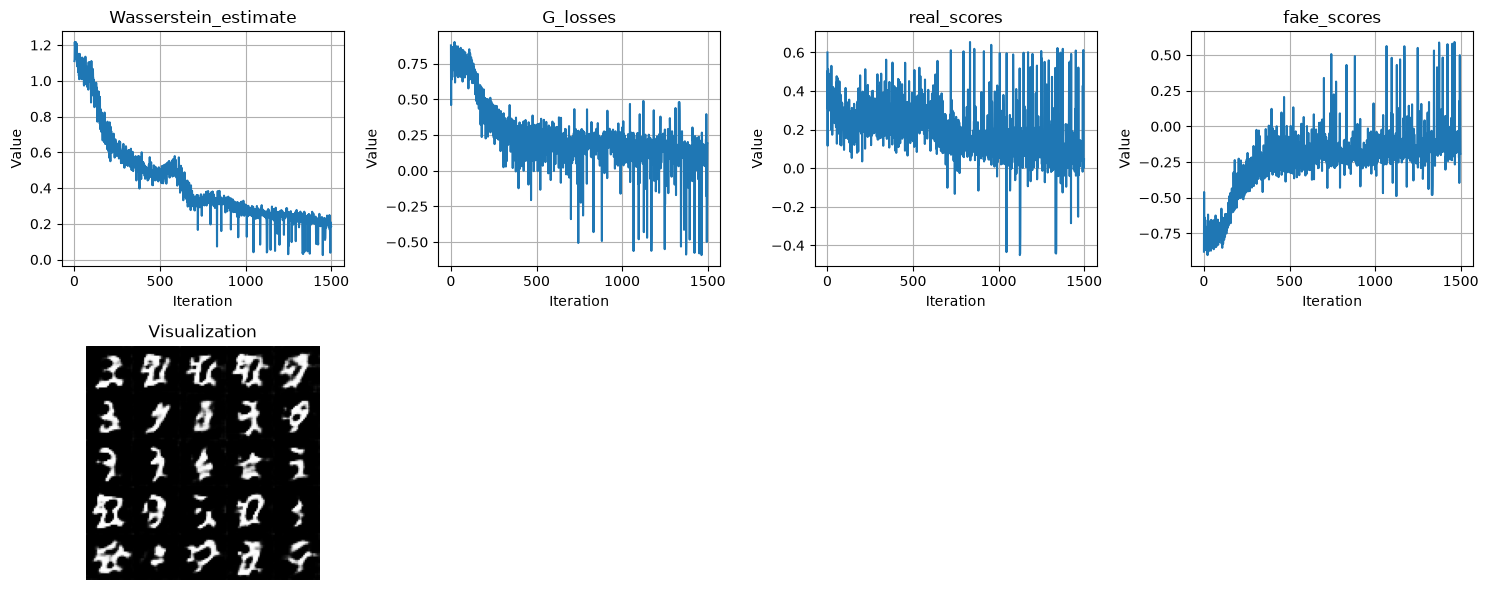

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:25<00:00,  6.46it/s]


Epoch 9/20


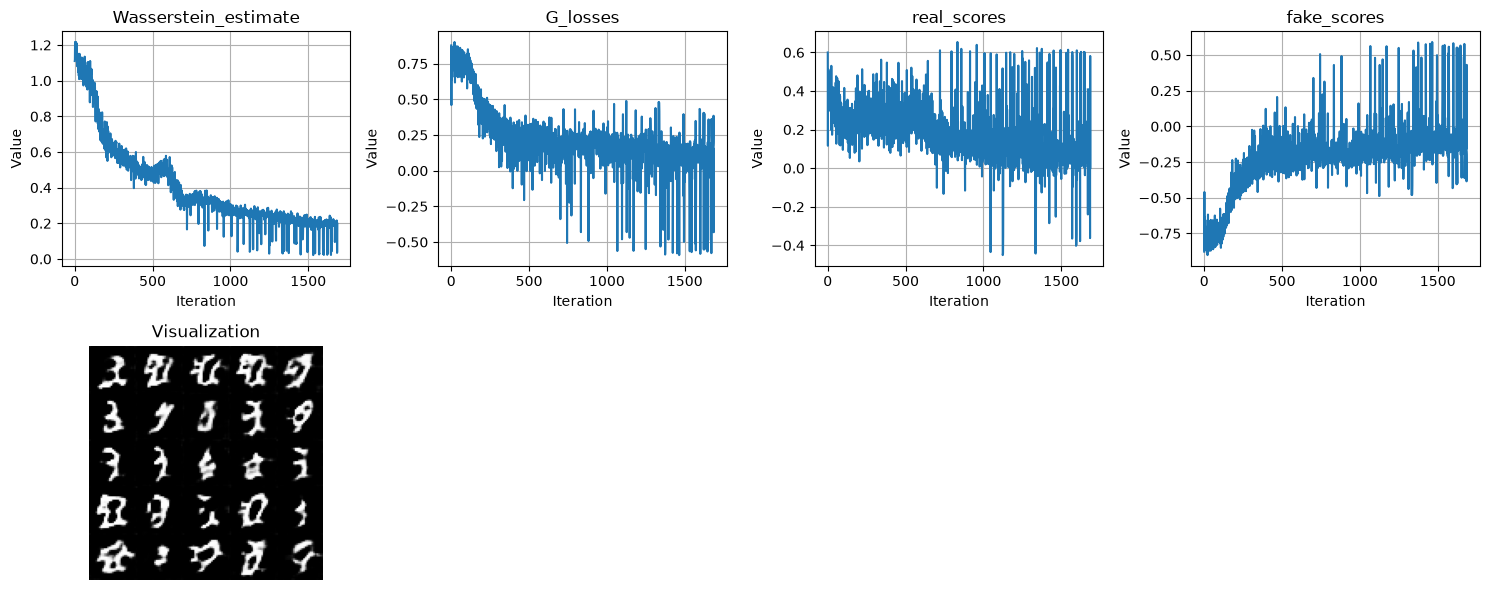

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:25<00:00,  6.47it/s]


Epoch 10/20


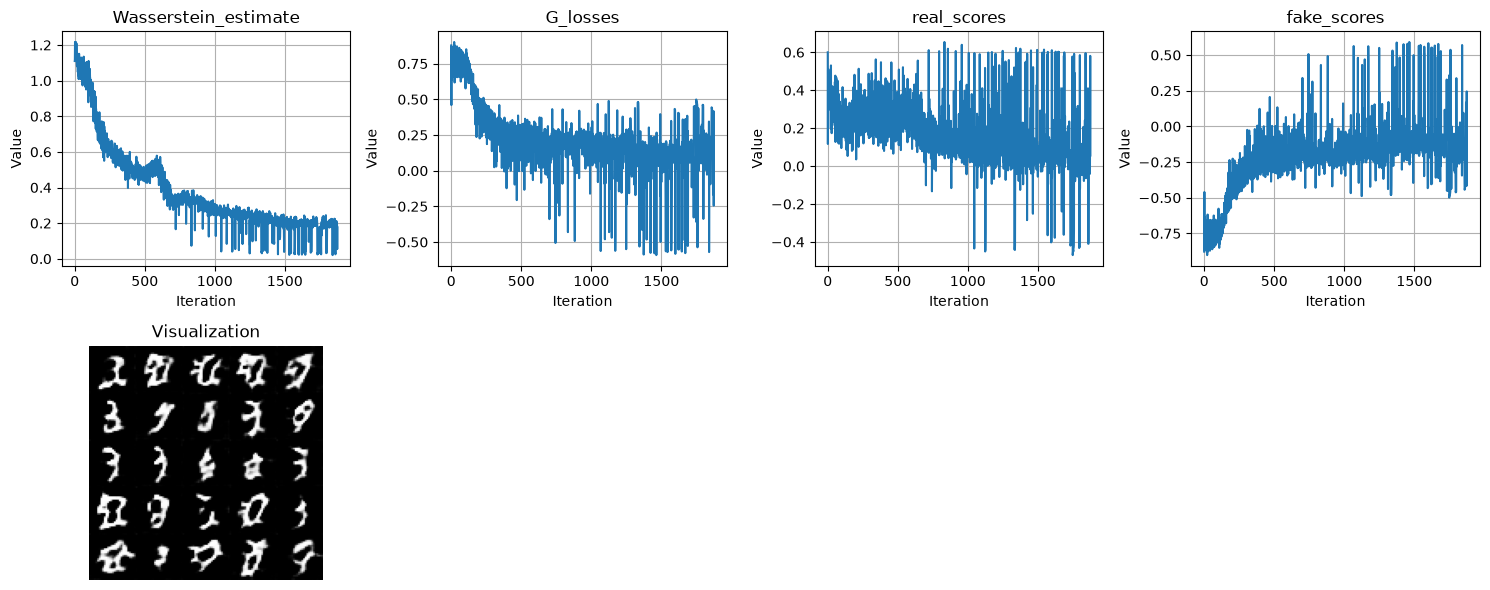

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:24<00:00,  6.47it/s]


Epoch 11/20


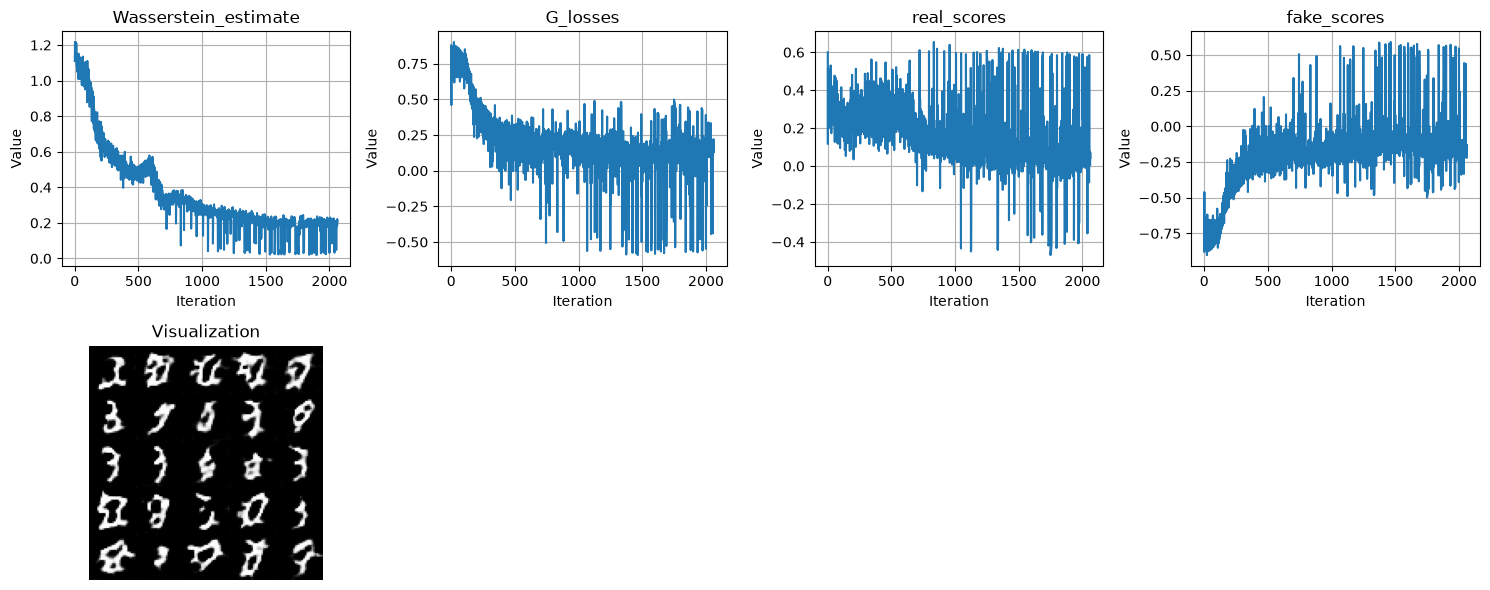

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:25<00:00,  6.42it/s]


Epoch 12/20


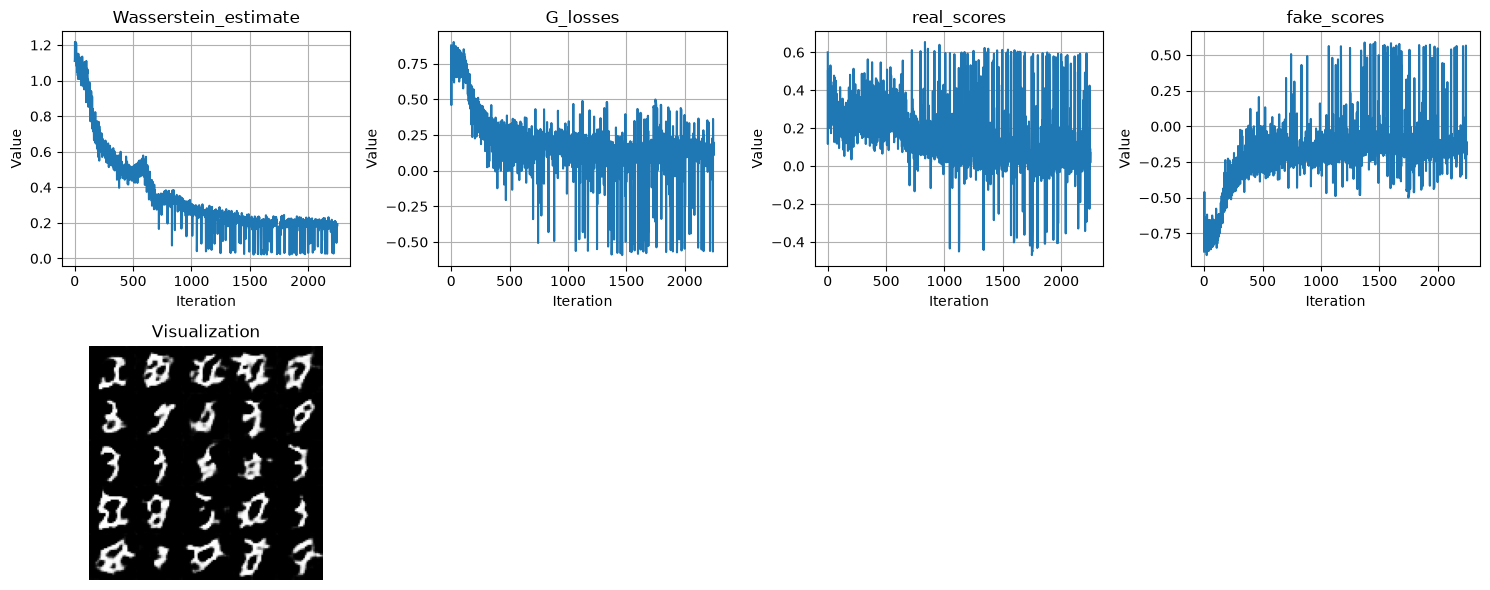

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:24<00:00,  6.49it/s]


Epoch 13/20


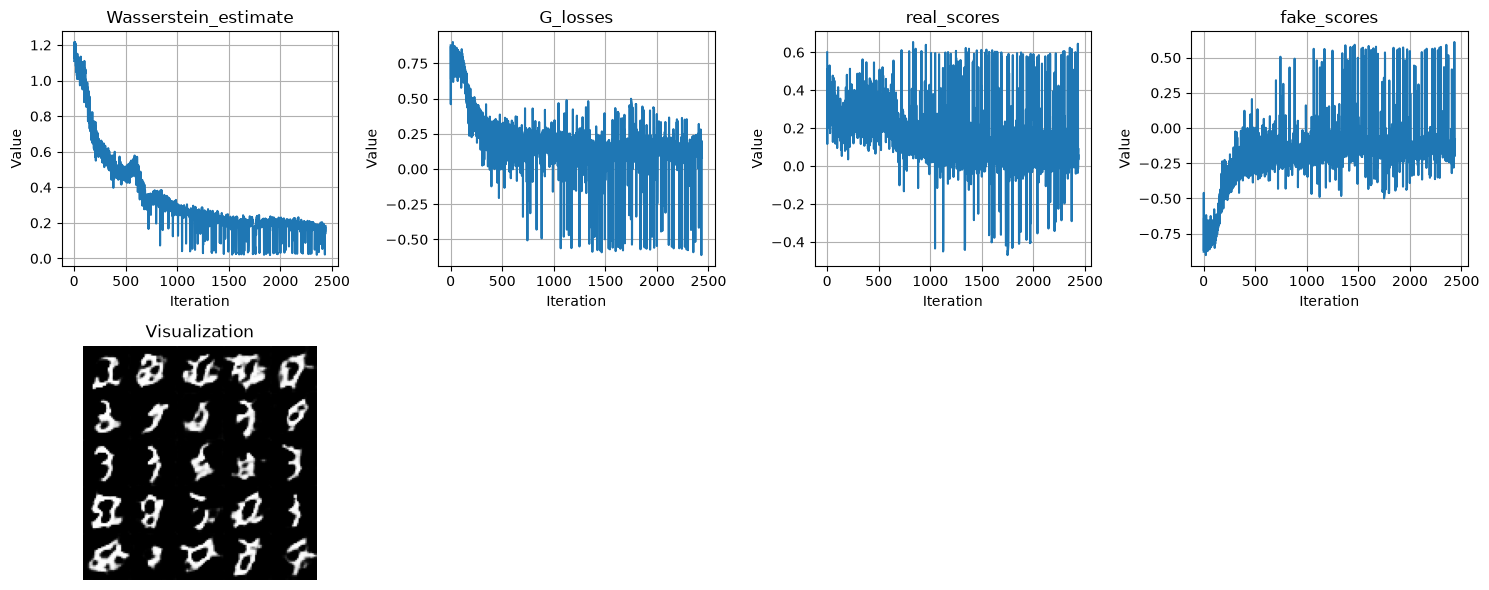

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:24<00:00,  6.51it/s]


Epoch 14/20


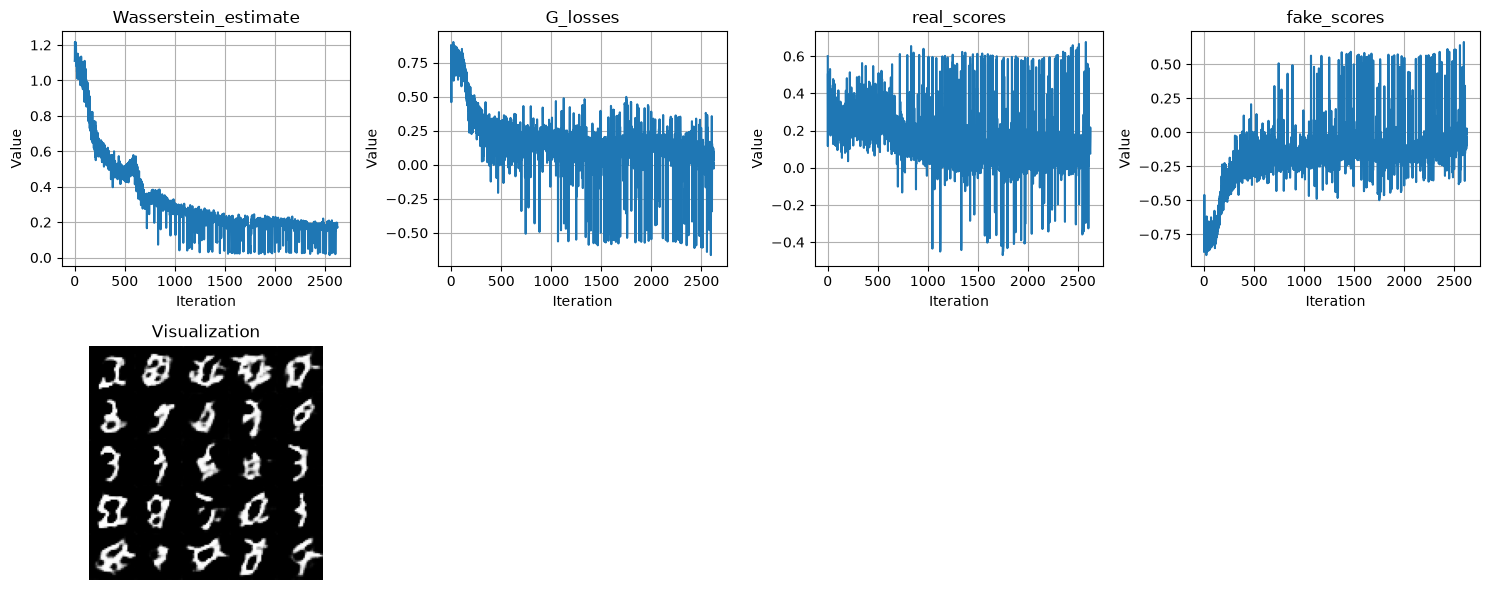

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:22<00:00,  6.58it/s]


Epoch 15/20


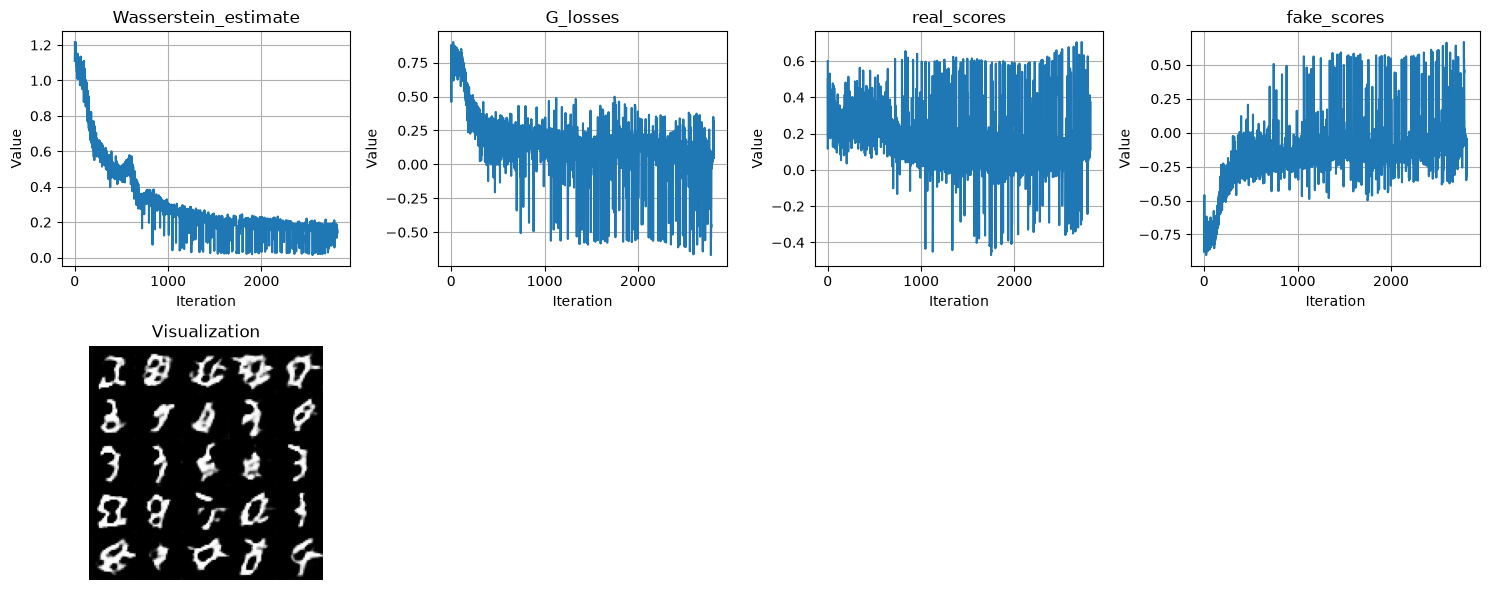

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:21<00:00,  6.62it/s]


Epoch 16/20


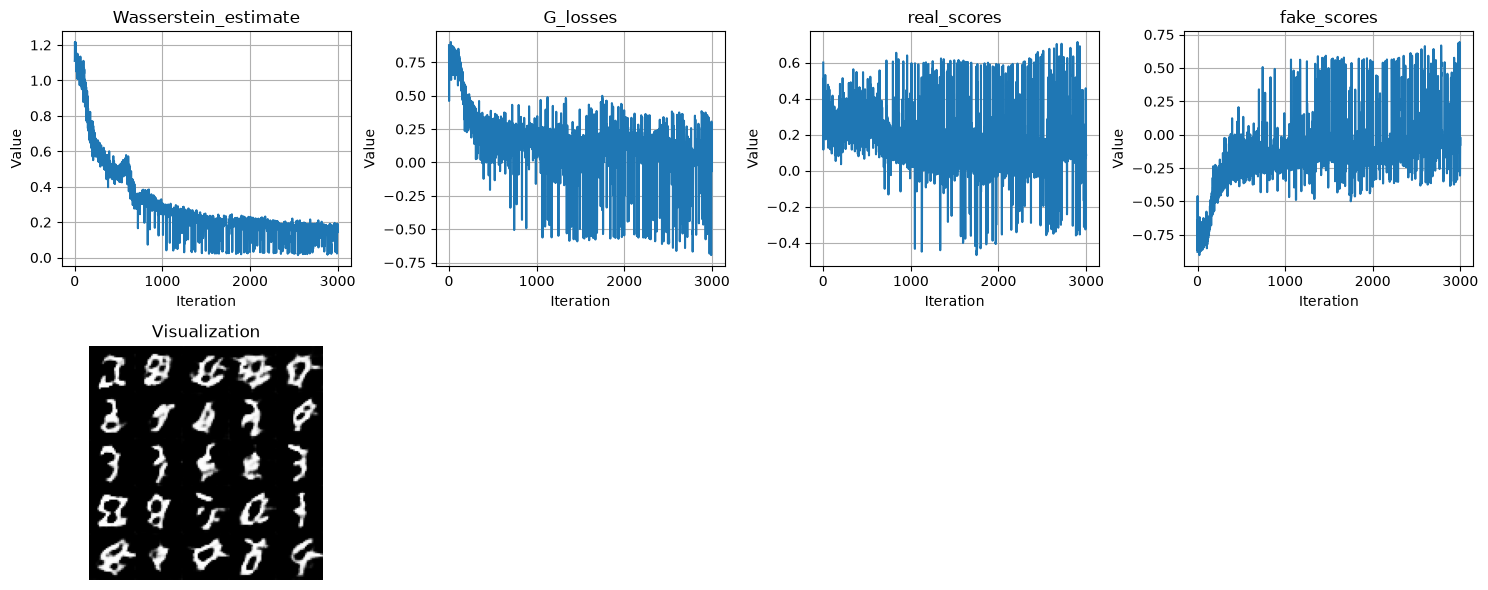

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:22<00:00,  6.58it/s]


Epoch 17/20


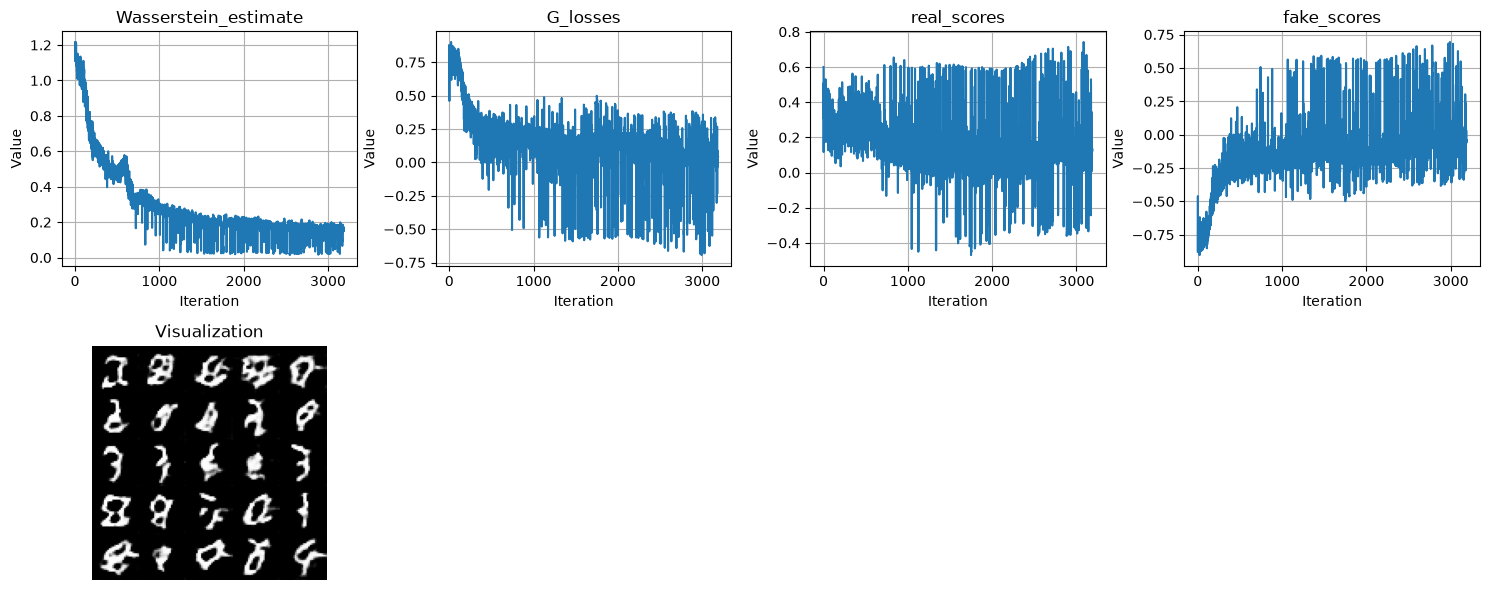

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:20<00:00,  6.70it/s]


Epoch 18/20


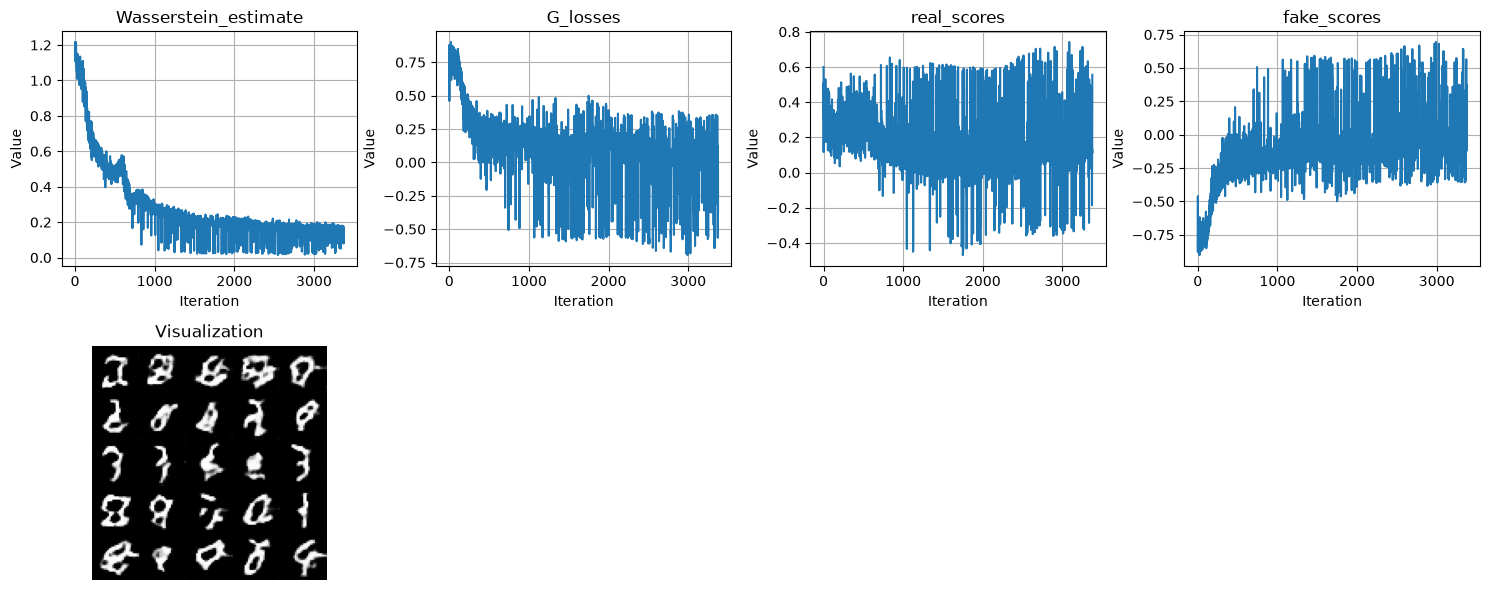

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:18<00:00,  6.77it/s]


Epoch 19/20


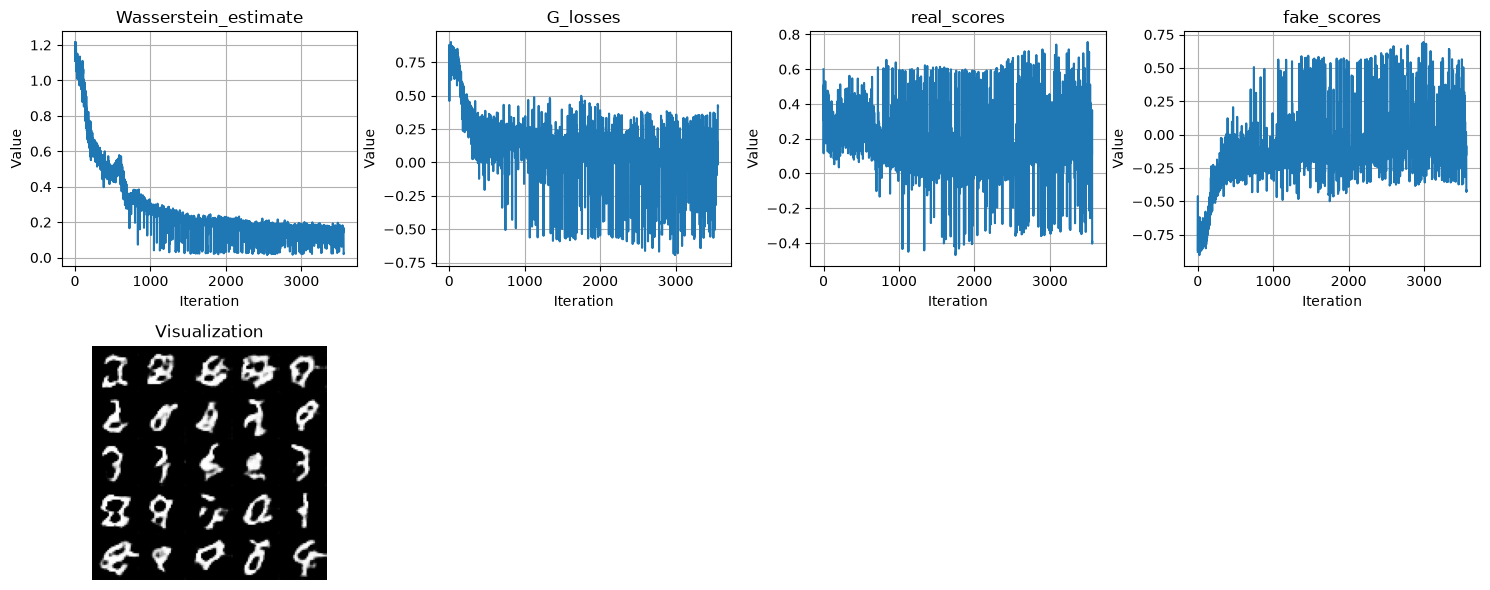

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 938/938 [02:18<00:00,  6.75it/s]


Epoch 20/20


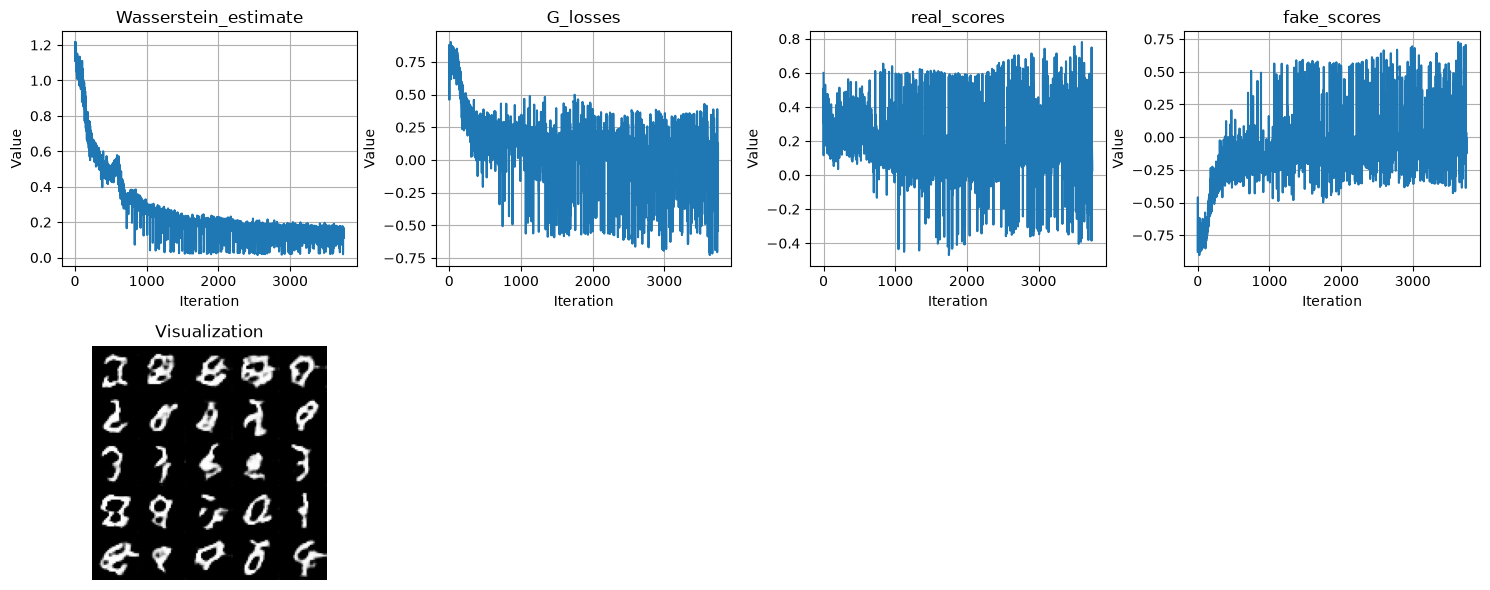

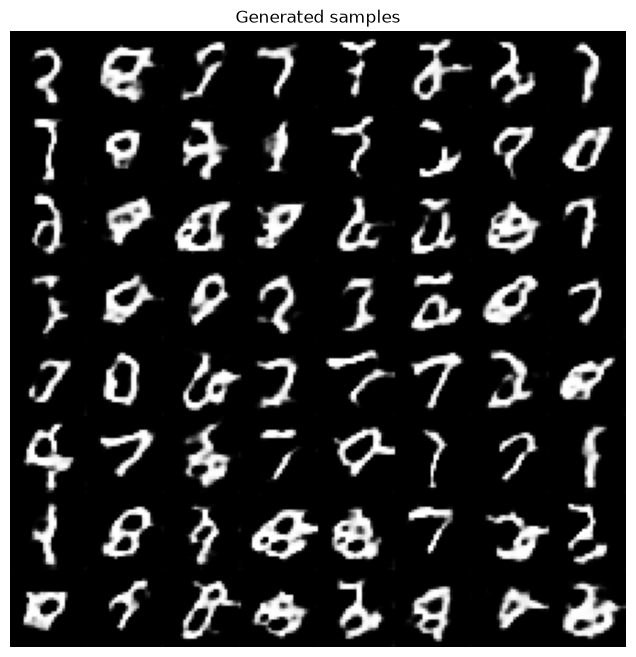

In [39]:
train_wgan(wgan_generator, critic, train_loader, num_epochs=20)